# MTM field widths: GS2 $\phi$ and $A_\parallel$ equivalent Gaussian widths in $\theta_b$, width laws, predicted GFTM settings

Fusion_PhD-bhx7.17. The user (2026-11-17): use the extent-to-width transformation to get the width of each GS2 MTM's $\phi$ and
$A_\parallel$ separately, look at their distributions, fit width laws, and ask whether one set of GFTM settings can resolve both.

**The conversion is analytic, in the basis coordinate.** TGLF and GFTM expand each field in $\psi_n(x)\propto H_n(x)e^{-x^2/2}$ with
$x=\theta_b/\mathrm{WIDTH}$, where $\theta_b=2\pi l_\parallel/L_{\rm turn}$ is the arc length along the field line, not $\theta$.
pyrokinetics now maps $\theta\to\theta_b$ exactly from each sample's geometry: `FieldLine.compute_basis_angle` (pyro PR #617, the
cumulative form of `compute_length_per_turn`). In $\theta_b$, the 95 % extent of $|f|^2$ (pyro `Extent`) is
- $E=2.772\,W$ for an even field, $|\psi_0|^2\propto e^{-x^2}$;
- $E=3.953\,W$ for an odd field, $|\psi_1|^2\propto x^2e^{-x^2}$.

An MTM has tearing parity: $A_\parallel$ even, $\phi$ odd. So $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/2.772$ and $W_\phi=E^{\theta_b}_\phi/3.953$.
No runs are calibrated against. The notebook checks the map against GFTM itself (NBASIS-2 eigenfunctions are pure Hermite functions
in $\theta_b$) and against qp5.49's run-calibrated KBM widths.

**Populations.** GS2 `pyro_cube_avg` of NSTX_MTM n1000 (fit) and n300 (out of sample), as the law2 refit (`mtm_extent_law_refit`):
label MTM ($T>0.15$, $\omega<0$), $\gamma>0$, `growth_rate_tolerance` $<0.01$. A field whose $|f|^2$ has more than 1 % beyond
$0.9\max|\theta|$ touches the box: its extent, and so its width, is a lower bound (right-censored).

In [1]:
import os
from multiprocessing import get_context
from pathlib import Path
import time
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, StrMethodFormatter
from scipy import optimize, stats
from scipy.stats import chi2, norm
from pyrokinetics import Pyro, PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine
from general_analysis import mode_classification as mc

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams["lines.marker"] = ""     # the style marks every line; reference lines (axvline/axhline) must not carry dots
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "mtm_field_widths"
plots_dir.mkdir(parents=True, exist_ok=True)
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

draws = {"n1000": "beta_q_shat_ky_n1000", "n300": "beta_q_shat_ky_n300"}
arms = {"m11_new": "m11_new", "law2 rule": "extent_rule_tf035_law2", "law2 maxbasis": "extent_maxbasis_law2_s100", "fw174": "gftm_fw174"}
m11_width = 5.89285              # registry gftm_m11_new: FIND_WIDTH F, WIDTH 5.89285 (its cube does not record the width)
fields = ["phi", "apar"]
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
mtm_parity = {"phi": "odd", "apar": "even"}
kbm_parity = {"phi": "even", "apar": "odd"}
tolerance_gate, edge_gate = 1e-2, 1e-2
target_error = 0.03              # qp5.49: the extent-convergence criterion behaves like a Gaussian at 3 % relative L2 error
nbasis_cap, nxgrid_cap, nxgrid_floor = 59, 65, 14
kbm_cases = ["SPR-045", "M1", "R4", "R3"]
check_widths = [0.2, 0.4, 0.8, 1.6]
calibration_widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5,
                      1.6, 1.9218, 2.3083, 2.7726, 3.3302, 4.0]   # qp5.49's fixed-width GFTM NBASIS-2 ladder


def extent_95(power, coordinate):
    # pyro's 95 % Extent of |f|^2 over `coordinate` (theta or theta_b), finite points only
    keep = np.isfinite(power)
    return float(Extent._compute(xr.DataArray(power[keep][None], dims=("sample", "theta"), coords=dict(theta=coordinate[keep])), 0.95)[0][0])


def edge_fraction(power, theta):
    # share of |f|^2 beyond 0.9 of the run's own theta box (law2 refit's box-contact measure)
    keep = np.isfinite(power)
    power, theta = power[keep], theta[keep]
    return float(np.trapezoid(power * (abs(theta) > 0.9 * abs(theta).max()), theta) / np.trapezoid(power, theta))

## The analytic factors, and pyro's `Extent` on the models
qp5.43 (`basis_resolution_rule`) quoted $4.32\sigma$ for the odd model, measured with the `Extent` of that time. pyro's `Extent` is
now the central-95 % rule (2.5 % in each tail). On a fine grid it gives the $\chi^2_3$ quantile, $3.953$, for $x\,e^{-x^2/2}$; 4.32 is
not reproduced and is superseded.

In [2]:
analytic_factor = {"even": 2 * norm.ppf(0.975) / np.sqrt(2), "odd": 2 * np.sqrt(chi2.ppf(0.95, 3) / 2)}
x_fine = np.linspace(-12, 12, 200001)
model = {"even": lambda x: np.exp(-x ** 2 / 2), "odd": lambda x: x * np.exp(-x ** 2 / 2)}
for parity in model:
    measured = extent_95(model[parity](x_fine) ** 2, x_fine)
    assert abs(measured - analytic_factor[parity]) < 1e-3, (parity, measured)
    print(f"{parity}: pyro Extent {measured:.4f}, analytic {analytic_factor[parity]:.4f}")
assert abs(extent_95(model["odd"](x_fine) ** 2, x_fine) - 4.32) > 0.3

even: pyro Extent 2.7718, analytic 2.7718
odd: pyro Extent 3.9534, analytic 3.9534


## Check 1: the pyro map against GFTM itself
At NBASIS 2, GFTM's $\phi$ is $\psi_0$ and its $A_\parallel$ is $\psi_1$ (a KBM: ballooning parity). On $x=\theta_b/W$ they must be
$e^{-x^2/2}$ and $x\,e^{-x^2/2}$. Per sample, field and WIDTH: the relative $L^2$ residual of $|f|$ against the best multiple of
$|{\rm model}|$, with $x$ from $\theta_b$ (pyro map) and, for contrast, from $\theta$; and the extent in $\theta_b$ over $W$ against
the model's extent **on the same $\theta_b$ points** (GFTM writes only 289 points over $\pm9\pi$, so at small WIDTH the grid,
not the map, sets the extent's last digits). Samples: qp5.49's fixed-width leaves `galF_w*_nb2_nx32`, all four KBM databases.

In [3]:
def check_leaf(spec):
    case, width = spec
    leaf = (data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{f'w{width:.4f}'.replace('.', 'p')}_nb2_nx32")
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data
    gamma = output.growth_rate.pint.dequantify()
    assert (gamma.fillna(-np.inf).argmax("mode") == 0).all()                      # IBRANCH -1: mode 0 is dominant
    rows = []
    for i, name in enumerate(output.sample_name.values):
        dominant = output.isel(sample=i, mode=0)  # mode0-guard-allow: argmax == 0 asserted above
        if not np.isfinite(float(gamma.isel(sample=i, mode=0))):  # mode0-guard-allow: argmax == 0 asserted above
            continue
        theta = output.theta.values
        basis_angle = FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset())).compute_basis_angle(theta)
        for field, parity in kbm_parity.items():
            amplitude = np.abs(dominant[field].pint.dequantify().values.ravel())
            if not np.isfinite(amplitude).all() or amplitude.max() == 0:
                continue
            row = dict(case=case, sample=str(name), width=width, field=field)
            for coordinate_name, coordinate in (("theta_b", basis_angle), ("theta", theta)):
                shape = np.abs(model[parity](coordinate / width))
                weight = np.gradient(coordinate)
                scale = (amplitude * shape * weight).sum() / (shape ** 2 * weight).sum()
                row[f"residual_{coordinate_name}"] = np.sqrt(((amplitude - scale * shape) ** 2 * weight).sum() / (amplitude ** 2 * weight).sum())
            row["extent_over_width"] = extent_95(amplitude ** 2, basis_angle) / width
            row["model_extent_over_width"] = extent_95(model[parity](basis_angle / width) ** 2, basis_angle) / width
            row["extent_theta_over_width"] = extent_95(amplitude ** 2, theta) / width
            rows.append(row)
    return pd.DataFrame(rows)


with get_context("fork").Pool(n_cpu) as pool:
    code_check = pd.concat(pool.map(check_leaf, [(case, width) for case in kbm_cases for width in check_widths]), ignore_index=True)
code_check["extent_over_model"] = code_check.extent_over_width / code_check.model_extent_over_width
code_check_summary = code_check.groupby(["field", "width"]).agg(
    n=("sample", "size"), residual_theta_b_median=("residual_theta_b", "median"), residual_theta_b_q90=("residual_theta_b", lambda r: r.quantile(0.9)),
    residual_theta_median=("residual_theta", "median"), extent_over_model_median=("extent_over_model", "median"),
    extent_over_width_median=("extent_over_width", "median"), extent_theta_over_width_median=("extent_theta_over_width", "median"))
code_check_summary.to_csv(plots_dir / "code_check_summary.csv")
print(code_check_summary.round(4).to_string())
assert (code_check_summary.residual_theta_b_median < 0.02).all()
assert (abs(code_check_summary.extent_over_model_median - 1) < 0.02).all()

               n  residual_theta_b_median  residual_theta_b_q90  residual_theta_median  extent_over_model_median  extent_over_width_median  extent_theta_over_width_median
field width                                                                                                                                                               
apar  0.2    718                   0.0009                0.0017                 0.4883                    0.9992                    4.2215                          6.3814
      0.4    738                   0.0008                0.0013                 0.4378                    0.9996                    4.2352                          5.7919
      0.8    734                   0.0009                0.0025                 0.3112                    1.0004                    4.1338                          4.8591
      1.6    721                   0.0005                0.0020                 0.1577                    0.9998                    3.9727       

## Check 2: KBMs, analytic $\theta_b$ widths against qp5.49's run-calibrated widths
The 738 GS2-KBMs of the four `kbm_free` hypercubes. Analytic: $W_\phi=E^{\theta_b}_\phi/2.772$, $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/3.953$.
Run-calibrated (qp5.49, re-derived here): the WIDTH at which the NBASIS-2 GFTM extent in $\theta$ equals the GS2 extent in $\theta$,
interpolated in $\log$ over the 24 fixed widths, with $E(W)$ made non-decreasing and out-of-range targets censored.

In [4]:
def gftm_nb2_extents(spec):
    case, width = spec
    leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{f'w{width:.4f}'.replace('.', 'p')}_nb2_nx32"
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data.set_index(sample="sample_name")
    assert (output.growth_rate.pint.dequantify().fillna(-np.inf).argmax("mode") == 0).all()
    dominant = output.isel(mode=0)  # mode0-guard-allow: argmax == 0 asserted above
    theta = output.theta.values
    return pd.DataFrame({"case": case, "sample": [str(name) for name in output.sample.values], "fixed_width": width,
                         **{f"{field}_extent": [extent_95(np.abs(row) ** 2, theta) if np.isfinite(row).any() else np.nan
                                                for row in dominant[field].pint.dequantify().squeeze("kx").transpose("sample", "theta").values]
                            for field in fields}})


def gs2_kbm(case):
    leaf = data_root / "GS2/Runs/LATIN_HYPERCUBE" / case / "kbm_free"
    gs2_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    kbm_leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free/galF_w1p0000_nb16_nx32"
    population = [str(name) for name in PyroHypercube(pyroscan_json=kbm_leaf / "pyroscan.json", load_base_pyro=True).pyro_dict]
    output = gs2_scan.gk_output.data.set_index(sample="sample_name")
    rows = []
    for name in population:
        squared = {field: output[f"{field}_squared"].sel(sample=name).pint.dequantify().squeeze().values for field in fields}
        theta = output.theta.values
        basis_angle = FieldLine(gs2_scan.sample_pyro(name, gk_output=xr.Dataset())).compute_basis_angle(theta)
        rows.append(dict(case=case, sample=name, **{f"{field}_extent_gs2": extent_95(squared[field], theta) for field in fields},
                         **{f"{field}_width_analytic": extent_95(squared[field], basis_angle) / analytic_factor[kbm_parity[field]] for field in fields}))
    return pd.DataFrame(rows)


with get_context("fork").Pool(n_cpu) as pool:
    ladder = pd.concat(pool.map(gftm_nb2_extents, [(case, width) for case in kbm_cases for width in calibration_widths]), ignore_index=True)
    kbm = pd.concat(pool.map(gs2_kbm, kbm_cases), ignore_index=True)
assert len(kbm) == 738
for field in fields:
    curves = ladder.pivot_table(index=["case", "sample"], columns="fixed_width", values=f"{field}_extent")
    calibrated = {}
    for (case, sample), curve in curves.iterrows():
        target = kbm.set_index(["case", "sample"]).loc[(case, sample), f"{field}_extent_gs2"]
        curve = curve.dropna()
        monotone_extent = np.maximum.accumulate(curve.values)
        calibrated[(case, sample)] = (0.0 if target < monotone_extent[0] else np.inf if target > monotone_extent[-1]
                                      else np.exp(np.interp(np.log(target), np.log(monotone_extent), np.log(curve.index.values))))
    kbm = kbm.join(pd.Series(calibrated).rename(f"{field}_width_calibrated"), on=["case", "sample"])
    kbm[f"{field}_ratio"] = kbm[f"{field}_width_analytic"] / kbm[f"{field}_width_calibrated"]
finite = {field: np.isfinite(kbm[f"{field}_ratio"]) & (kbm[f"{field}_width_calibrated"] > 0) for field in fields}
kbm_summary = pd.DataFrame({field: dict(n=int(finite[field].sum()), median_analytic=kbm[f"{field}_width_analytic"].median(),
                                        median_calibrated=kbm[f"{field}_width_calibrated"].median(),
                                        ratio_median=kbm[f"{field}_ratio"][finite[field]].median(),
                                        ratio_q10=kbm[f"{field}_ratio"][finite[field]].quantile(0.1),
                                        ratio_q90=kbm[f"{field}_ratio"][finite[field]].quantile(0.9)) for field in fields}).T
kbm_summary.to_csv(plots_dir / "kbm_crosscheck_summary.csv")
print(kbm_summary.round(3).to_string())

          n  median_analytic  median_calibrated  ratio_median  ratio_q10  ratio_q90
phi   737.0            0.713              0.616         1.094      1.042      1.291
apar  722.0            0.439              0.399         1.112      1.062      1.206


## GS2 MTMs: label, map to $\theta_b$, extent and width per field
Per sample, one `FieldLine` on the sample's own Pyro (its geometry, the cube's $A_\parallel$ attached) gives the tearing parameter $T$
and the map $\theta\to\theta_b$. The label is GA's `classify_T_omega`. Each field's extent is pyro's 95 % `Extent` of $|f|^2$ in
$\theta_b$ (and in $\theta$, for reference); $\phi$ and $A_\parallel$ even fractions (pyro `compute_linear_parity`) check the parity
assumption.

In [5]:
def load_gs2(draw):
    cube_dir = data_root / "GS2/Runs/LATIN_HYPERCUBE/NSTX_MTM" / draws[draw] / "pyro_cube_avg"
    scan = PyroHypercube(pyro=Pyro(gk_file=cube_dir / "pyroscan_base.input", gk_code="GS2"), pyroscan_json=cube_dir / "pyroscan.json",
                         base_directory=cube_dir.parent, file_name="gs2.in")
    scan.load_gk_output(netcdf_file=cube_dir / "cube.nc")
    return scan


projection_widths = np.geomspace(0.5, 32, 19)
n_project = 160


def hermite_functions(x, n=n_project):
    # orthonormal psi_n(x) = H_n(x) exp(-x^2/2) / sqrt(2^n n! sqrt(pi)), n = 0 .. n-1, by the stable recurrence (tglf_hermite.f90's)
    psi = np.zeros((n, len(x)))
    psi[0] = np.pi ** -0.25 * np.exp(-x ** 2 / 2)
    psi[1] = np.sqrt(2) * x * psi[0]
    for k in range(2, n):
        psi[k] = np.sqrt(2 / k) * x * psi[k - 1] - np.sqrt((k - 1) / k) * psi[k - 2]
    return psi


x_check = np.linspace(-40, 40, 40001)
gram = hermite_functions(x_check) @ hermite_functions(x_check).T * (x_check[1] - x_check[0])
assert np.allclose(gram, np.eye(n_project), atol=1e-8)                              # orthonormal to n = 159


def gs2_sample(args):
    draw, i = args
    scan = gs2_scans[draw]
    output = scan.gk_output.data.isel(sample=i)
    finite_theta = output.apar.pint.dequantify().dropna("theta").sortby("theta").theta     # GS2 grids are NaN-padded to the union
    fields_theta = {field: output[field].pint.dequantify().sel(theta=finite_theta) for field in fields}
    field_line = FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset(fields_theta)))
    theta = fields_theta["apar"].theta.values
    basis_angle = field_line.compute_basis_angle(theta)
    row = dict(draw=draw, sample=str(output.sample_name.values), ky=float(output.ky), shat=float(output.shat), q=float(output.q),
               beta=float(output.beta), gamma=float(output.growth_rate.pint.dequantify()),
               omega=mc.ION_DIRECTION * float(output.mode_frequency.pint.dequantify()),
               tolerance=float(output.growth_rate_tolerance.pint.dequantify()),
               T=float(field_line.compute_linear_tearing_parameter().squeeze()),
               phi_even=float(field_line.compute_linear_parity("phi").squeeze()), apar_even=float(field_line.compute_linear_parity("apar").squeeze()),
               stretch=float(np.gradient(basis_angle, theta)[np.argmin(abs(theta))]))
    for field in fields:
        power = np.abs(fields_theta[field].values) ** 2
        row[f"{field}_extent_theta"] = extent_95(power, theta)
        row[f"{field}_extent"] = extent_95(power, basis_angle)
        row[f"{field}_edge"] = edge_fraction(power, theta)
        row[f"{field}_width"] = row[f"{field}_extent"] / analytic_factor[mtm_parity[field]]
        weight = power * np.gradient(basis_angle)
        row[f"{field}_tail_fraction"] = float(weight[abs(basis_angle) > np.pi].sum() / weight.sum())   # |f|^2 beyond the first poloidal turn
        # projection of the complex field onto the code's basis psi_n(theta_b / WIDTH) / sqrt(WIDTH), as qp5.43: relative L2 error after N functions
        values, step = fields_theta[field].values.ravel(), np.gradient(basis_angle)
        for j, width in enumerate(projection_widths):
            coefficients = (hermite_functions(basis_angle / width) / np.sqrt(width)) @ (values * step)
            error = np.sqrt(np.maximum(1 - np.cumsum(np.abs(coefficients) ** 2) / (np.abs(values) ** 2 * step).sum(), 0))
            row[f"{field}_projected_needed_{j}"] = int(np.argmax(error <= target_error)) + 1 if (error <= target_error).any() else np.inf
            for nbasis in (24, nbasis_cap):
                row[f"{field}_projected_error_{nbasis}_{j}"] = float(error[nbasis - 1])
    return row


gs2_scans = {draw: load_gs2(draw) for draw in draws}
with get_context("fork").Pool(n_cpu) as pool:
    gs2 = pd.DataFrame(pool.map(gs2_sample, [(draw, i) for draw in draws for i in range(gs2_scans[draw].gk_output.data.sizes["sample"])], chunksize=8))
gs2["label"] = mc.classify_T_omega(gs2)
check = gs2[(gs2.draw == "n1000") & (gs2["sample"] == "iteration_33")].iloc[0]
assert round(check.ky, 5) == 0.58085 and round(check.shat, 5) == 1.32921        # Fusion_PhD-jmw0 guard: cube coordinates
mtm = gs2[(gs2.label == "MTM") & (gs2.gamma > 0) & (gs2.tolerance < tolerance_gate)].copy()
for field in fields:
    mtm[f"{field}_censored"] = mtm[f"{field}_edge"] >= edge_gate
mtm["ratio"] = mtm.phi_width / mtm.apar_width                                     # s^2 = W_phi / W_A_par
mtm["ratio_censored"] = mtm.phi_censored | mtm.apar_censored
counts = gs2.groupby("draw").agg(loaded=("sample", "size"), MTM=("label", lambda label: (label == "MTM").sum())).join(
    mtm.groupby("draw").agg(MTM_unstable_converged=("sample", "size"), phi_censored=("phi_censored", "sum"), apar_censored=("apar_censored", "sum"),
                            phi_even_median=("phi_even", "median"), apar_even_median=("apar_even", "median"),
                            phi_odd_share=("phi_even", lambda even: (even < 0.5).mean()), apar_even_share=("apar_even", lambda even: (even > 0.5).mean()),
                            stretch_median=("stretch", "median"), apar_tail_median=("apar_tail_fraction", "median"),
                            phi_tail_median=("phi_tail_fraction", "median")))
print(counts.round(3).to_string())

       loaded  MTM  MTM_unstable_converged  phi_censored  apar_censored  phi_even_median  apar_even_median  phi_odd_share  apar_even_share  stretch_median  apar_tail_median  phi_tail_median
draw                                                                                                                                                                                         
n1000    1000  757                     683            58             35              0.0               1.0            1.0              1.0           1.047             0.112            0.599
n300      300  226                     202            14              9              0.0               1.0            1.0              1.0           1.047             0.130            0.616


### What sets $W_{A_\parallel}$: one peak at $\theta_b=0$, or a train of peaks at $\theta_b=2\pi p$
$W_{A_\parallel}$ clusters at discrete values (the width-law figure below shows them as horizontal bands). The share of $|A_\parallel|^2$
beyond the first poloidal turn ($|\theta_b|>\pi$) separates the two shapes; below, $W_{A_\parallel}$ against that share, and one
eigenfunction from each band (median-$\gamma$ MTM of the band, n1000), $|f|^2$ normalised to its peak, against $\theta_b/\pi$, with the
Gaussian (dashed) that has the same extent.

                n  apar_width_median  apar_tail_median  phi_width_median  shat_median  q_median  ky_median
apar_band                                                                                                 
(0.0, 3.0]    386              1.120             0.002             5.789        2.285     2.522      0.425
(3.0, 8.0]    222              5.737             0.239             7.533        1.474     3.794      0.237
(8.0, 12.5]   107             10.239             0.615            10.567        0.965     3.758      0.188
(12.5, 17.5]   63             14.697             0.698            13.177        0.690     3.237      0.139
(17.5, 25.0]   54             19.500             0.769            17.511        0.522     3.372      0.107
(25.0, inf]    53             32.751             0.873            24.401        0.246     3.022      0.081


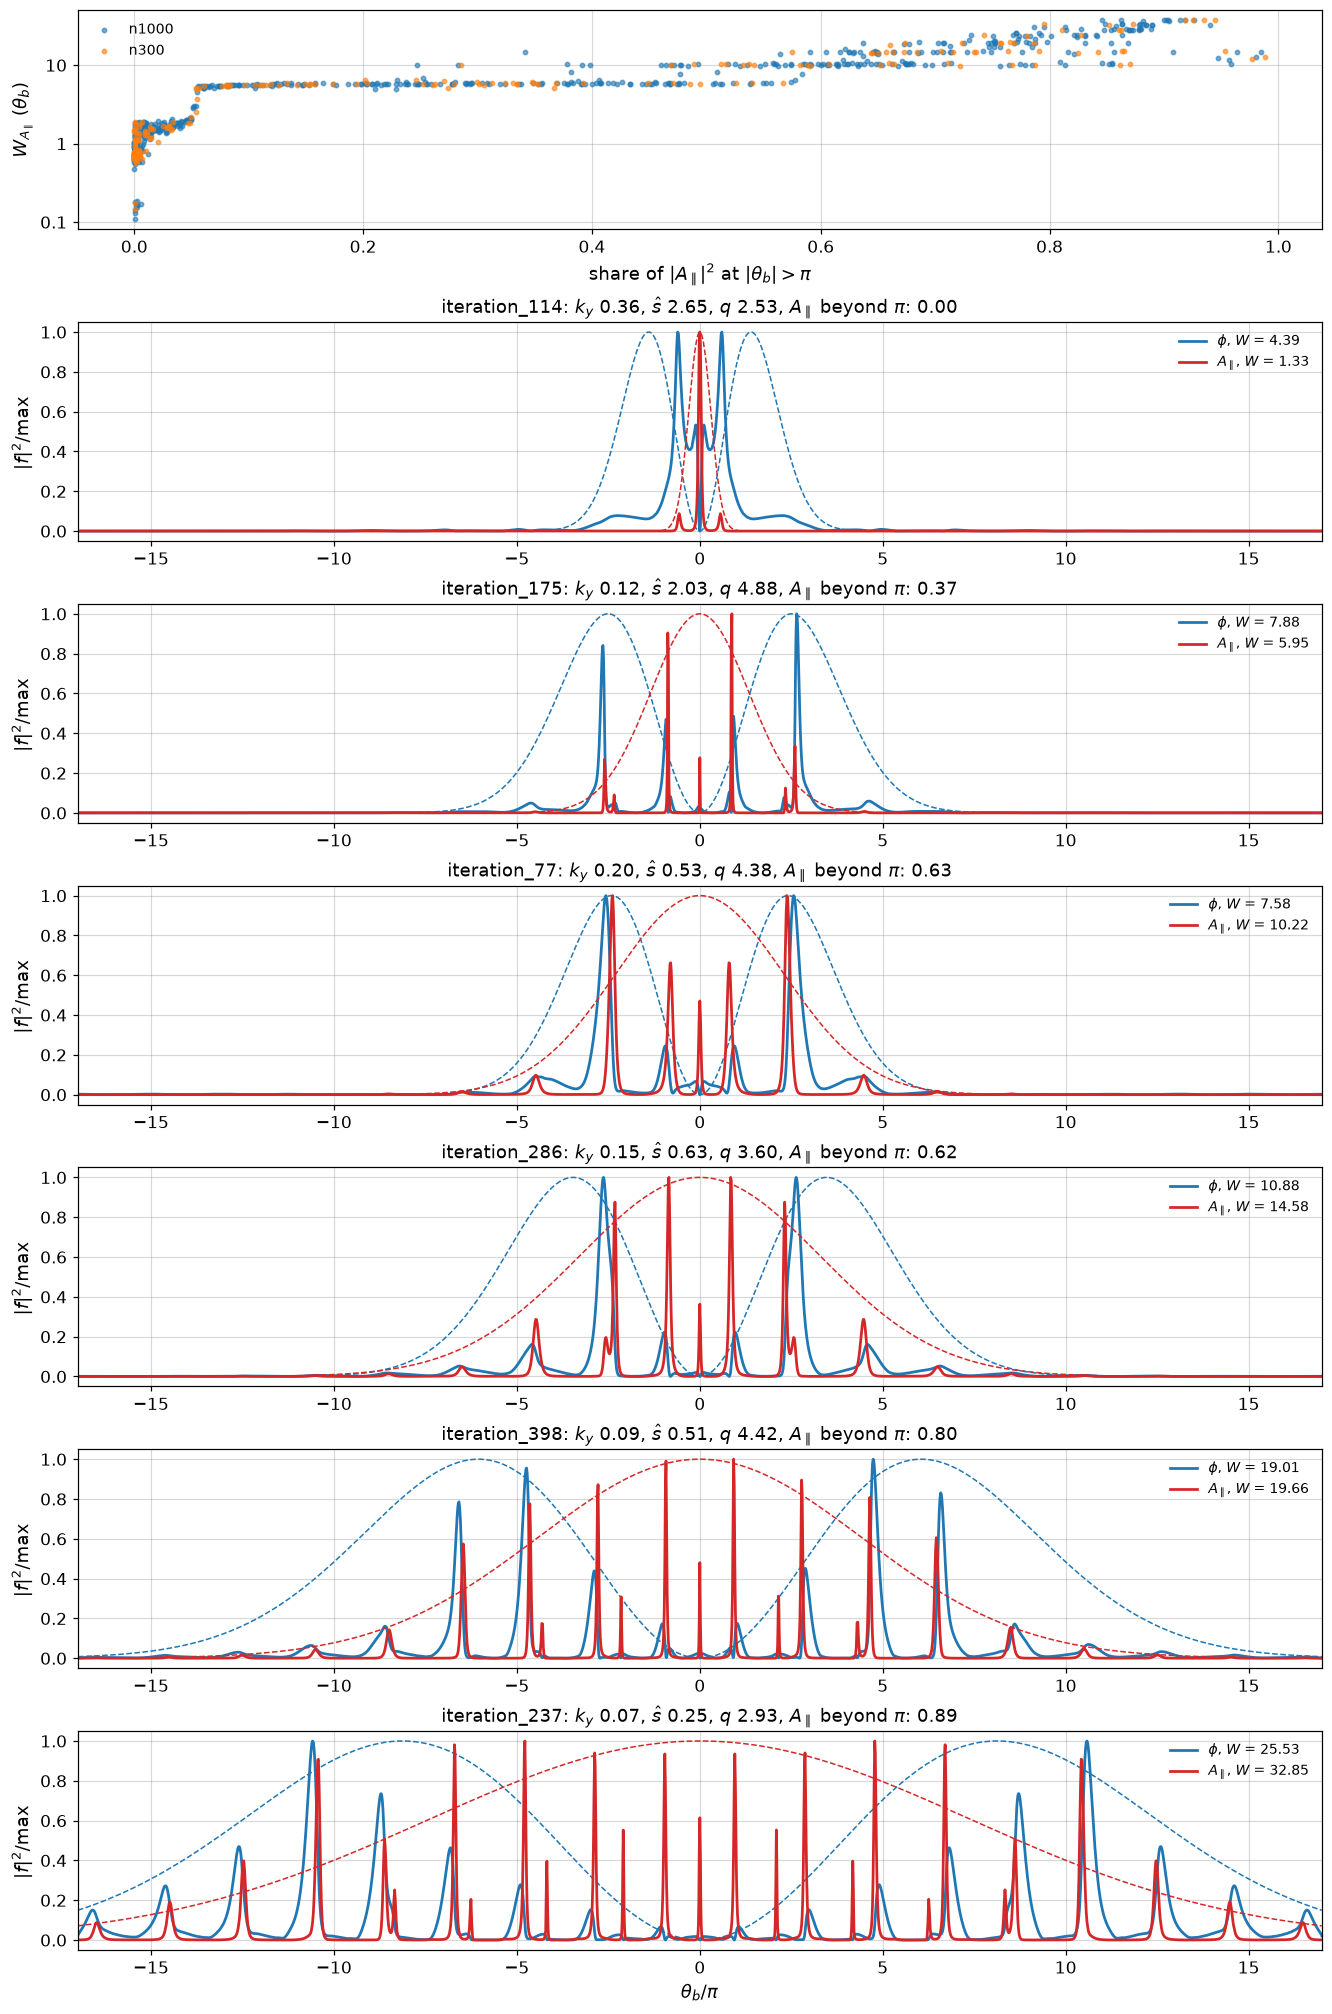

In [6]:
band_edges = [0, 3, 8, 12.5, 17.5, 25, np.inf]
mtm["apar_band"] = pd.cut(mtm.apar_width, band_edges)
print(mtm.groupby("apar_band", observed=True).agg(n=("sample", "size"), apar_width_median=("apar_width", "median"),
                                                 apar_tail_median=("apar_tail_fraction", "median"), phi_width_median=("phi_width", "median"),
                                                 shat_median=("shat", "median"), q_median=("q", "median"), ky_median=("ky", "median")).round(3).to_string())
examples = [rows.iloc[(rows.gamma - rows.gamma.median()).abs().argmin()] for _, rows in mtm[mtm.draw == "n1000"].groupby("apar_band", observed=True)
            if len(rows) >= 5]
fig, axes = plt.subplots(1 + len(examples), 1, figsize=(12, 2.6 * (1 + len(examples))), constrained_layout=True)
for draw, colour in zip(draws, ("C0", "C1")):
    rows = mtm[mtm.draw == draw]
    axes[0].scatter(rows.apar_tail_fraction, rows.apar_width, s=8, color=colour, alpha=0.6, label=draw)
axes[0].set(yscale="log", xlabel=r"share of $|A_\parallel|^2$ at $|\theta_b|>\pi$", ylabel=r"$W_{A_\parallel}$ ($\theta_b$)")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:g}")); axes[0].yaxis.set_minor_locator(NullLocator()); axes[0].legend(fontsize=9)
for ax, example in zip(axes[1:], examples):
    scan = gs2_scans["n1000"]
    output = scan.gk_output.data.set_index(sample="sample_name").sel(sample=example["sample"])
    finite_theta = output.apar.pint.dequantify().dropna("theta").sortby("theta").theta
    basis_angle = FieldLine(scan.sample_pyro(example["sample"], gk_output=xr.Dataset())).compute_basis_angle(finite_theta.values)
    for field, colour in zip(fields, ("C0", "C3")):
        power = np.abs(output[field].pint.dequantify().sel(theta=finite_theta).values) ** 2
        ax.plot(basis_angle / np.pi, power / power.max(), color=colour, marker="", label=f"{field_label[field]}, $W$ = {example[f'{field}_width']:.2f}")
        width = example[f"{field}_width"]
        ax.plot(basis_angle / np.pi, np.abs(model[mtm_parity[field]](basis_angle / width)) ** 2 / np.abs(model[mtm_parity[field]](basis_angle / width)).max() ** 2,
                color=colour, ls="--", lw=1, marker="")
    ax.set(xlim=(-17, 17), ylabel=r"$|f|^2/\max$", title=f"{example['sample']}: $k_y$ {example.ky:.2f}, $\\hat s$ {example.shat:.2f}, $q$ {example.q:.2f}, "
           f"$A_\\parallel$ beyond $\\pi$: {example.apar_tail_fraction:.2f}")
    ax.legend(fontsize=9, loc="upper right")
axes[-1].set_xlabel(r"$\theta_b/\pi$")
fig.savefig(plots_dir / "apar_bands_eigenfunctions.png", dpi=150); fig.savefig(plots_dir / "apar_bands_eigenfunctions.pdf")
plt.show()

## Distributions of $W_\phi$, $W_{A_\parallel}$ and $s^2=W_\phi/W_{A_\parallel}$
Kept modes in blue; censored modes (box contact, a lower bound on the width) stacked in red. Medians are Kaplan–Meier medians
where censoring matters (below).

     draw quantity    n  censored  km_q10  km_q25  km_q50  km_q75  km_q90
0   n1000      phi  683        58   4.208   5.643   7.882  12.655  18.336
1   n1000     apar  683        35   0.712   1.318   5.605  10.252  19.409
2   n1000    ratio  683        58   0.872   1.063   2.024   4.630  11.745
3    n300      phi  202        14   4.351   5.968   8.052  12.487  16.272
4    n300     apar  202         9   0.732   1.274   5.629  10.241  17.992
5    n300    ratio  202        14   0.847   1.055   1.696   4.052  11.168
6  pooled      phi  885        72   4.209   5.711   7.959  12.545  17.606
7  pooled     apar  885        44   0.718   1.312   5.620  10.251  19.341
8  pooled    ratio  885        72   0.864   1.060   1.908   4.615  11.702


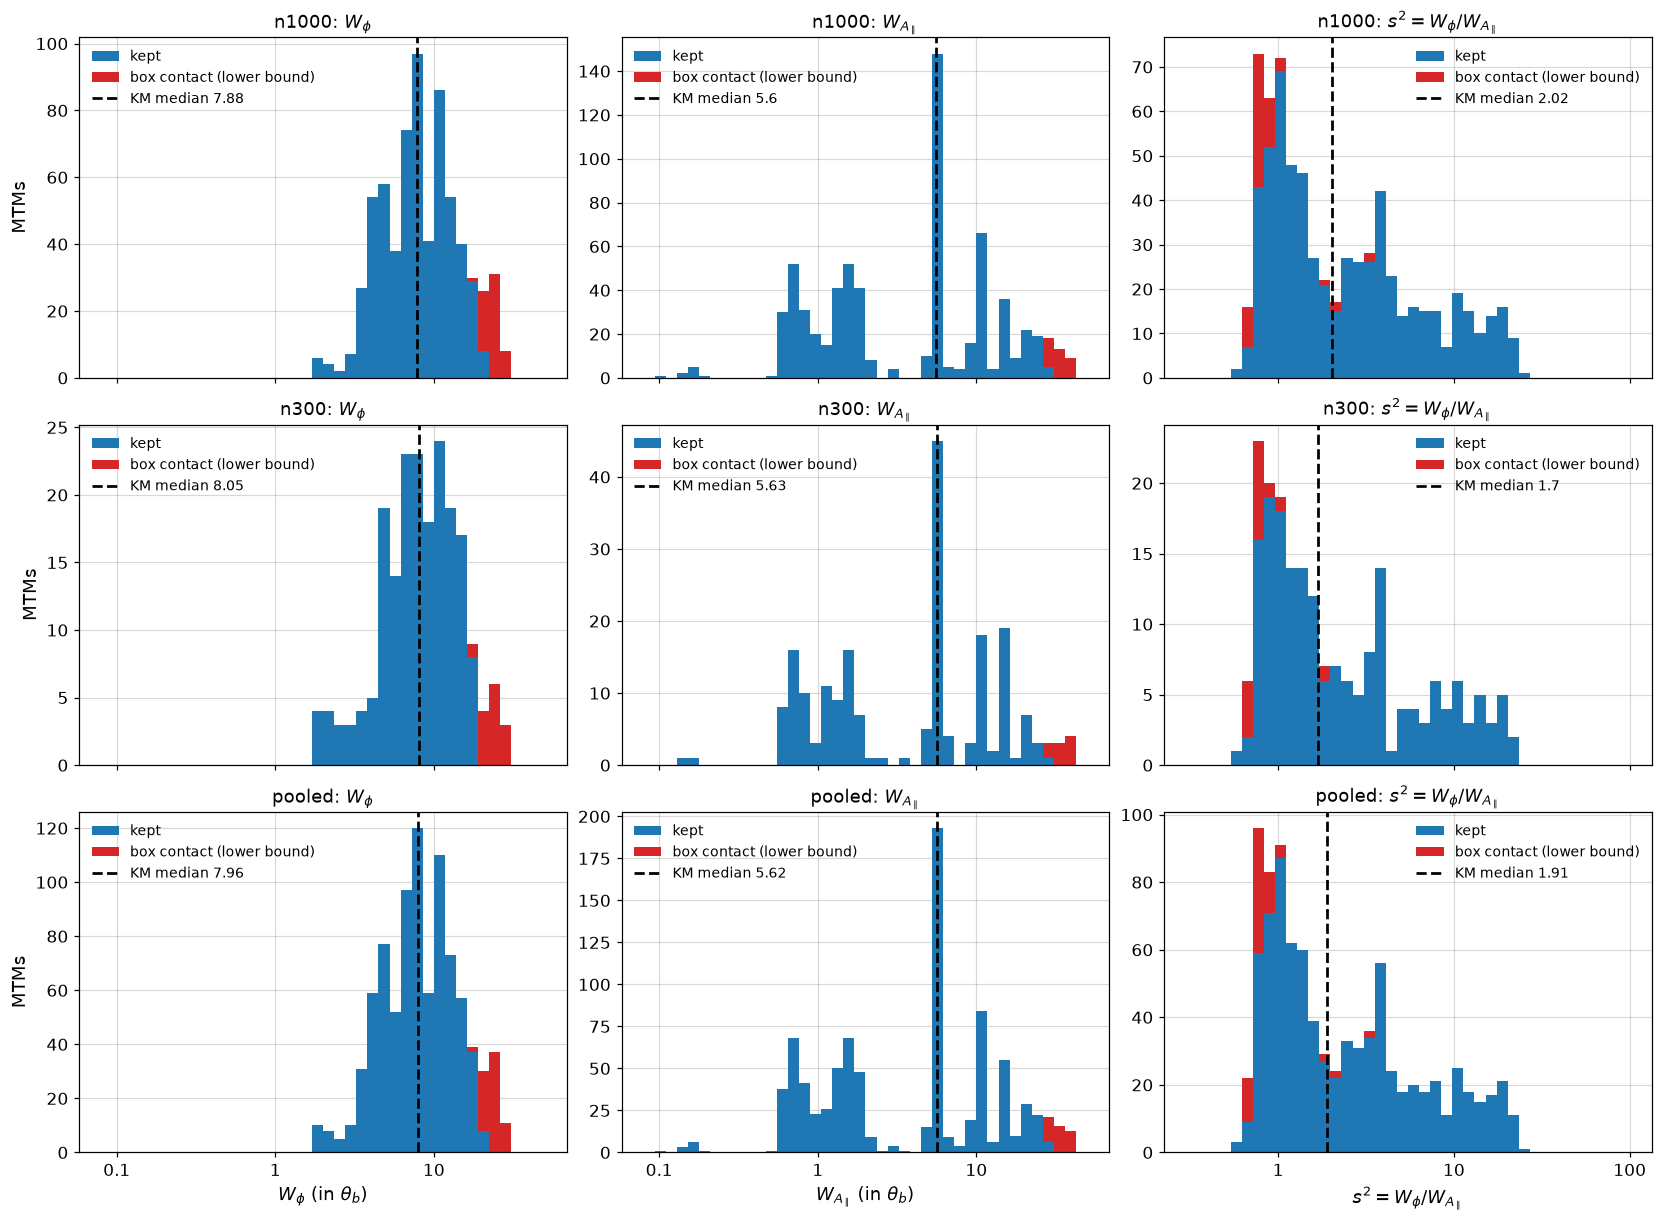

In [7]:
def km_quantile(values, censored, p):
    # p-quantile of right-censored values (Kaplan-Meier); NaN if the estimate never reaches p
    order = np.argsort(values)
    values, censored = np.asarray(values)[order], np.asarray(censored)[order]
    survival = np.cumprod(1 - (~censored) / (len(values) - np.arange(len(values))))
    hit = np.nonzero(1 - survival >= p)[0]
    return values[hit[0]] if len(hit) else np.nan


quantities = {"phi": ("phi_width", "phi_censored", rf"$W_\phi$"), "apar": ("apar_width", "apar_censored", r"$W_{A_\parallel}$"),
              "ratio": ("ratio", "ratio_censored", r"$s^2=W_\phi/W_{A_\parallel}$")}
summary_rows = []
for draw in (*draws, "pooled"):
    rows = mtm if draw == "pooled" else mtm[mtm.draw == draw]
    for quantity, (column, censored, _) in quantities.items():
        summary_rows.append(dict(draw=draw, quantity=quantity, n=len(rows), censored=int(rows[censored].sum()),
                                 **{f"km_q{int(100 * p)}": km_quantile(rows[column].values, rows[censored].values, p) for p in (0.1, 0.25, 0.5, 0.75, 0.9)}))
width_summary = pd.DataFrame(summary_rows)
width_summary.to_csv(plots_dir / "width_summary.csv", index=False)
print(width_summary.round(3).to_string())

bins = {"phi": np.geomspace(0.08, 50, 41), "apar": np.geomspace(0.08, 50, 41), "ratio": np.geomspace(0.3, 100, 41)}
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex="col", constrained_layout=True)
for row, draw in enumerate((*draws, "pooled")):
    rows = mtm if draw == "pooled" else mtm[mtm.draw == draw]
    for column, (quantity, (value, censored, label)) in enumerate(quantities.items()):
        ax = axes[row, column]
        clipped = rows[value].clip(bins[quantity][0] * 1.01, bins[quantity][-1] * 0.99)
        ax.hist([clipped[~rows[censored]], clipped[rows[censored]]], bins=bins[quantity], stacked=True, color=["C0", "C3"],
                label=["kept", "box contact (lower bound)"])
        median = width_summary.set_index(["draw", "quantity"]).loc[(draw, quantity), "km_q50"]
        ax.axvline(median, color="k", ls="--", label=f"KM median {median:.3g}")
        ax.set_xscale("log"); ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.xaxis.set_minor_locator(NullLocator())
        ax.set_title(f"{draw}: {label}")
        ax.legend(fontsize=9)
        if row == 2:
            ax.set_xlabel(label + (r" (in $\theta_b$)" if quantity != "ratio" else ""))
    axes[row, 0].set_ylabel("MTMs")
fig.savefig(plots_dir / "width_distributions.png", dpi=150); fig.savefig(plots_dir / "width_distributions.pdf")
plt.show()

Low-level view: each MTM's $W_{A_\parallel}$ against $W_\phi$, coloured by $\hat s$; dotted lines of constant $s^2$.

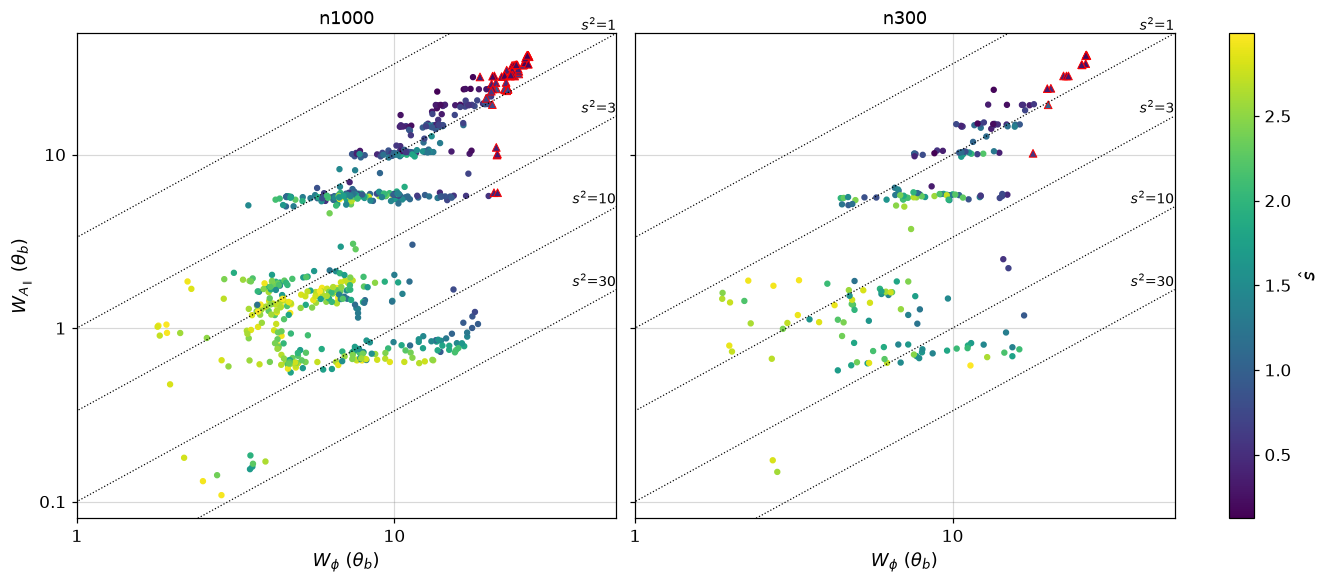

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True, constrained_layout=True)
for ax, draw in zip(axes, draws):
    rows = mtm[mtm.draw == draw]
    scatter = ax.scatter(rows.phi_width[~rows.ratio_censored], rows.apar_width[~rows.ratio_censored], c=rows.shat[~rows.ratio_censored], s=10, cmap="viridis")
    ax.scatter(rows.phi_width[rows.ratio_censored], rows.apar_width[rows.ratio_censored], c=rows.shat[rows.ratio_censored], s=26, marker="^",
               cmap="viridis", norm=scatter.norm, edgecolors="r", linewidths=0.6)
    for ratio in (0.3, 1, 3, 10, 30):
        line = np.array([0.08, 50])
        ax.plot(line, line / ratio, "k:", lw=0.8, marker="")
        ax.annotate(f"$s^2$={ratio}", (line[1], line[1] / ratio), fontsize=9, ha="right", va="bottom")
    ax.set(xscale="log", yscale="log", xlim=(1, 50), ylim=(0.08, 50), title=draw, xlabel=r"$W_\phi$ ($\theta_b$)")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(StrMethodFormatter("{x:g}")); axis.set_minor_locator(NullLocator())
axes[0].set_ylabel(r"$W_{A_\parallel}$ ($\theta_b$)")
fig.colorbar(scatter, ax=axes, label=r"$\hat s$")
fig.savefig(plots_dir / "width_phi_vs_apar.png", dpi=150); fig.savefig(plots_dir / "width_phi_vs_apar.pdf")
plt.show()

## Width laws
Per field, $\ln W_f=c+a\ln k_y+b\ln\hat s+d\ln q$ on n1000, Tobit with the box-contact modes right-censored, 400-sample bootstrap 95 %
intervals; the margin is the Kaplan–Meier 95th percentile of $\ln(W/{\rm centre})$; coverage out of sample on n300. The fit and margin
code is the law2 refit's (`mtm_extent_law_refit_nstx.ipynb`). $k_y$, $\hat s$, $q$ are the cube coordinates.

                        0      1      2
quantity              phi   apar  ratio
prefactor_centre    9.176  1.098  9.104
margin_km95         1.432  2.274  3.089
ky_exponent         -0.32 -0.387  0.007
shat_exponent      -0.568 -1.322  0.565
q_exponent         -0.337  0.987 -1.368
ky_ci_half          0.019  0.054  0.052
shat_ci_half        0.032  0.063   0.07
q_ci_half           0.039  0.108  0.113
sigma               0.234  0.594  0.621
n                     683    683    683
n_censored             58     35     58
n1000_below         0.878  0.906  0.874
n1000_above_sure    0.041  0.047  0.041
n1000_undetermined  0.081  0.047  0.085
n1000_median_ratio  0.695  0.472  0.297
n300_below          0.906  0.911  0.901
n300_above_sure     0.025  0.045   0.03
n300_undetermined   0.069  0.045  0.069
n300_median_ratio   0.664  0.474  0.288
phi: W = 9.1756 ky^-0.320 shat^-0.568 q^-0.337  (centre; x 1.432 for the 95 % envelope), sigma 0.234
apar: W = 1.0977 ky^-0.387 shat^-1.322 q^+0.987  (centre; x

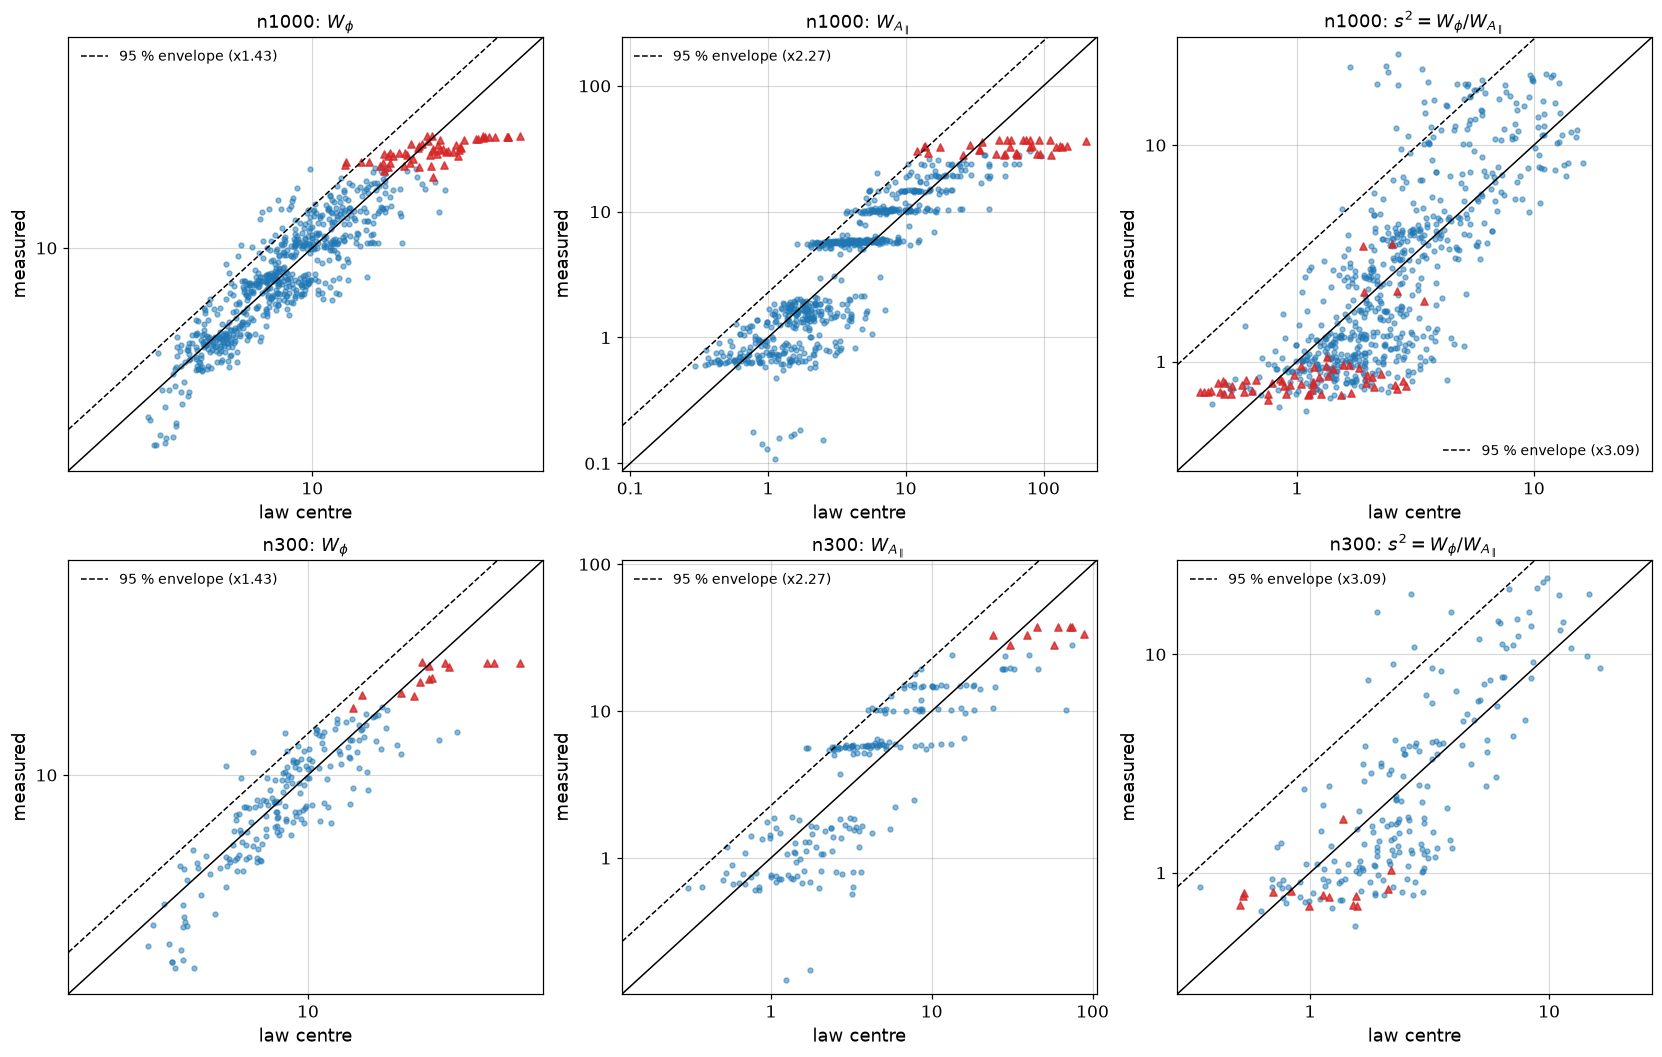

In [9]:
law_names = ["ky", "shat", "q"]


def design(rows):
    return np.column_stack([np.ones(len(rows))] + [np.log(rows[name].values) for name in law_names])


def tobit_fit(X, y, censored, start):
    def negative_log_likelihood(parameters):
        z = (y - X @ parameters[:-1]) / np.exp(parameters[-1])
        return -(stats.norm.logpdf(z[~censored]) - parameters[-1]).sum() - stats.norm.logsf(z[censored]).sum()
    return optimize.minimize(negative_log_likelihood, start, method="BFGS").x


def tobit(rows, value, censored, n_boot=400, seed=0):
    X, y, censored = design(rows), np.log(rows[value].values), rows[censored].values
    ols = np.linalg.lstsq(X[~censored], y[~censored], rcond=None)[0]
    start = np.r_[ols, np.log(np.std(y[~censored] - X[~censored] @ ols))]
    best = tobit_fit(X, y, censored, start)
    rng = np.random.default_rng(seed)
    boot = np.array([tobit_fit(X[pick], y[pick], censored[pick], best) for pick in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))])
    low, high = np.percentile(boot, [2.5, 97.5], axis=0)
    return dict(coefficients=best[:-1], low=low[:-1], high=high[:-1], sigma=float(np.exp(best[-1])), n=len(y), n_censored=int(censored.sum()))


def coverage(rows, value, censored, envelope):
    ratio = rows[value] / envelope
    return dict(below=float(((ratio <= 1) & ~rows[censored]).mean()), above_sure=float((ratio > 1).mean()),
                undetermined=float(((ratio <= 1) & rows[censored]).mean()), median_ratio=float(ratio[~rows[censored]].median()))


fit_rows = mtm[mtm.draw == "n1000"]
laws, law_rows = {}, []
for quantity in ("phi", "apar", "ratio"):
    value, censored, _ = quantities[quantity]
    law = tobit(fit_rows, value, censored)
    centre = lambda rows, law=law: np.exp(design(rows) @ law["coefficients"])
    margin = float(np.exp(km_quantile(np.log(fit_rows[value].values / centre(fit_rows)), fit_rows[censored].values, 0.95)))
    laws[quantity] = dict(**law, margin=margin, centre=centre)
    out_of_sample = mtm[mtm.draw == "n300"]
    law_rows.append(dict(quantity=quantity, prefactor_centre=np.exp(law["coefficients"][0]), margin_km95=margin,
                         **{f"{name}_exponent": law["coefficients"][j + 1] for j, name in enumerate(law_names)},
                         **{f"{name}_ci_half": (law["high"][j + 1] - law["low"][j + 1]) / 2 for j, name in enumerate(law_names)},
                         sigma=law["sigma"], n=law["n"], n_censored=law["n_censored"],
                         **{f"n1000_{key}": val for key, val in coverage(fit_rows, value, censored, centre(fit_rows) * margin).items()},
                         **{f"n300_{key}": val for key, val in coverage(out_of_sample, value, censored, centre(out_of_sample) * margin).items()}))
law_table = pd.DataFrame(law_rows)
law_table.to_csv(plots_dir / "width_laws.csv", index=False)
print(law_table.round(3).T.to_string())
for quantity, law in laws.items():
    print(f"{quantity}: W = {np.exp(law['coefficients'][0]):.4f} ky^{law['coefficients'][1]:+.3f} shat^{law['coefficients'][2]:+.3f} "
          f"q^{law['coefficients'][3]:+.3f}  (centre; x {law['margin']:.3f} for the 95 % envelope), sigma {law['sigma']:.3f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), constrained_layout=True)
for row, draw in enumerate(draws):
    rows = mtm[mtm.draw == draw]
    for column, quantity in enumerate(("phi", "apar", "ratio")):
        value, censored, label = quantities[quantity]
        ax = axes[row, column]
        predicted = laws[quantity]["centre"](rows)
        ax.scatter(predicted[~rows[censored]], rows[value][~rows[censored]], s=10, alpha=0.5, c="C0")
        ax.scatter(predicted[rows[censored]], rows[value][rows[censored]], s=22, marker="^", c="C3", alpha=0.8)
        limits = np.array([min(predicted.min(), rows[value].min()) * 0.8, max(predicted.max(), rows[value].max()) * 1.2])
        ax.plot(limits, limits, "k", lw=1, marker="")
        ax.plot(limits, limits * laws[quantity]["margin"], "k--", lw=1, marker="", label=f"95 % envelope (x{laws[quantity]['margin']:.2f})")
        ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits, title=f"{draw}: {label}", xlabel=f"law centre", ylabel=f"measured")
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(StrMethodFormatter("{x:.3g}")); axis.set_minor_locator(NullLocator())
        ax.legend(fontsize=9)
fig.savefig(plots_dir / "width_laws_measured_vs_law.png", dpi=150); fig.savefig(plots_dir / "width_laws_measured_vs_law.pdf")
plt.show()

## Predicted settings
A Gaussian of width $sW$ expanded in $\psi_n(x)$, $r=(s^2-1)/(s^2+1)$ (qp5.49, Mehler): even
$\lvert c_{2k}\rvert^2/\lVert f\rVert^2=\sqrt{1-r^2}\binom{2k}{k}(r^2/4)^k$, odd $\lvert c_{2k+1}\rvert^2/\lVert f\rVert^2=(1-r^2)^{3/2}(2k+1)\binom{2k}{k}(r^2/4)^k$.
$N_f(s,\epsilon)$ is the exact count at relative $L^2$ error $\epsilon=3\,\%$, with the odd form for $\phi$ and the even form for
$A_\parallel$ (MTM parity); the even count is bounded by $N\le2\ln(1/\epsilon)/\ln\lvert(s^2+1)/(s^2-1)\rvert$.

**The rule** (closed form from the laws, O(1) per case): WIDTH $=\sqrt{\hat W_\phi\hat W_{A_\parallel}}$ (law centres), NBASIS $=\max_f N_f$
at $s_f=W_f/{\rm WIDTH}$, NXGRID $=\max({\rm NBASIS}+6, 14)$, capped at 65 / 59. Evaluated with the law widths (what the rule sets) and
with each mode's measured widths (what it would need); the share above the cap is the share of MTMs that one WIDTH cannot cover.

draw                      n1000     n300
n                       683.000  202.000
width_median              5.258    5.273
nbasis_rule_median       10.000   10.000
rule_above_cap            0.010    0.015
measured_above_cap        0.110    0.129
oracle_above_cap          0.064    0.054
needed_measured_median   12.000   13.500
needed_oracle_median      6.000    6.000
phi_resolved              0.523    0.554
apar_resolved             0.649    0.579
both_resolved             0.363    0.322
seconds_per_case          0.000    0.000


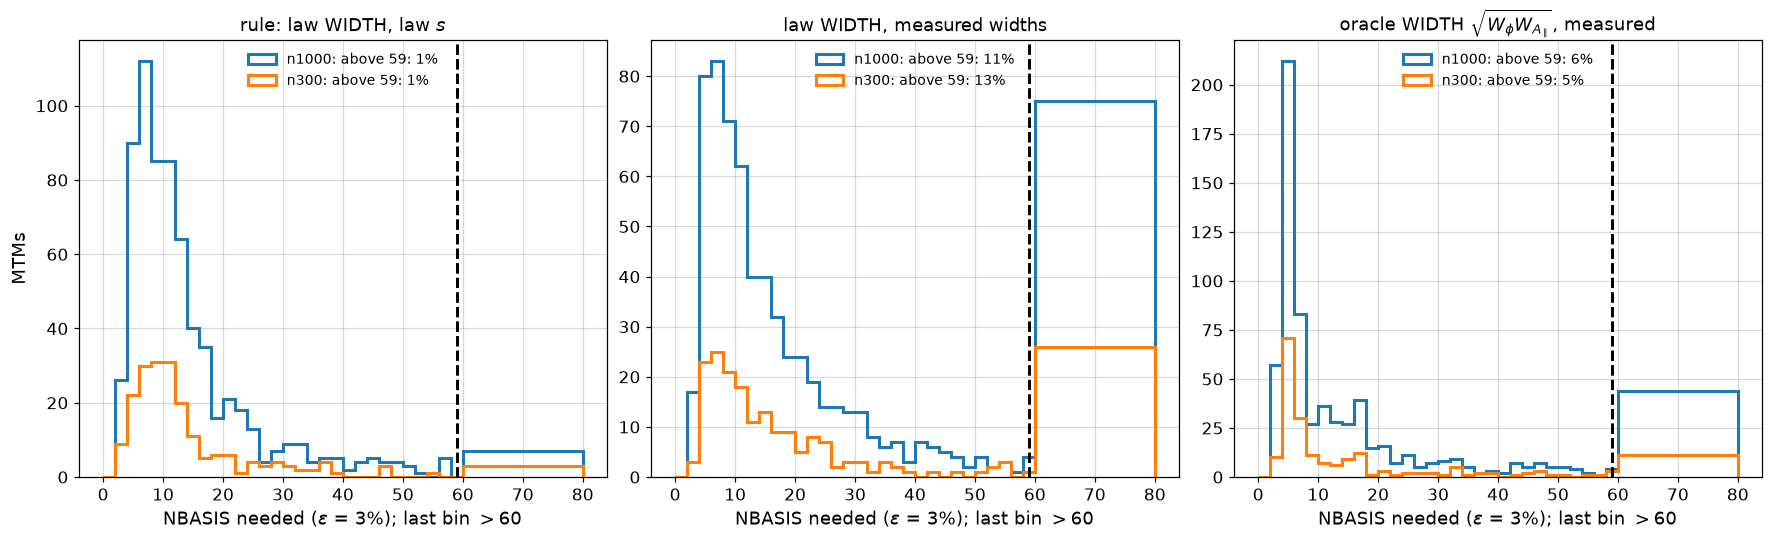

In [10]:
def model_fractions(s, parity, n_max=1200):
    r_squared = ((s ** 2 - 1) / (s ** 2 + 1)) ** 2
    k = np.arange(n_max // 2)
    central = np.cumprod(np.r_[1.0, (2 * k[1:] - 1) / (2 * k[1:])])        # binom(2k, k) / 4^k
    fractions = np.zeros(n_max)
    if parity == "even":
        fractions[0::2] = np.sqrt(1 - r_squared) * central * r_squared ** k
    else:
        fractions[1::2] = (1 - r_squared) ** 1.5 * (2 * k + 1) * central * r_squared ** k
    return fractions


def model_nbasis(s, parity, tolerance=target_error):
    error = np.sqrt(np.maximum(1 - np.cumsum(model_fractions(s, parity)), 0))
    return int(np.argmax(error <= tolerance)) + 1 if (error <= tolerance).any() else np.inf


def model_error(s, parity, nbasis):
    return float(np.sqrt(max(1 - model_fractions(s, parity)[:int(nbasis)].sum(), 0)))


for s in (0.3, 0.7, 3.0):
    assert model_nbasis(s, "even", 0.01) <= 2 * np.log(100) / np.log(abs((s ** 2 + 1) / (s ** 2 - 1))) + 1


def rule(rows):
    # closed form from the two width laws: WIDTH, NBASIS, NXGRID per case
    width_phi, width_apar = laws["phi"]["centre"](rows), laws["apar"]["centre"](rows)
    width = np.sqrt(width_phi * width_apar)
    needed = np.array([max(model_nbasis(s, mtm_parity["phi"]), model_nbasis(1 / s, mtm_parity["apar"])) for s in np.sqrt(width_phi / width_apar)])
    nbasis = np.minimum(needed, nbasis_cap)
    return pd.DataFrame(dict(width=width, nbasis_needed=needed, nbasis=nbasis, nxgrid=np.clip(nbasis + 6, nxgrid_floor, nxgrid_cap)), index=rows.index)


start = time.perf_counter()
settings = rule(mtm)
seconds_per_case = (time.perf_counter() - start) / len(mtm)
for field in fields:
    settings[f"s_{field}"] = mtm[f"{field}_width"] / settings.width
    settings[f"{field}_needed"] = [model_nbasis(s, mtm_parity[field]) for s in settings[f"s_{field}"]]
    settings[f"{field}_error"] = [model_error(s, mtm_parity[field], nbasis) for s, nbasis in zip(settings[f"s_{field}"], settings.nbasis)]
settings["needed_measured"] = settings[["phi_needed", "apar_needed"]].max(axis=1)
oracle_width = np.sqrt(mtm.phi_width * mtm.apar_width)
settings["needed_oracle"] = [max(model_nbasis(s, mtm_parity["phi"]), model_nbasis(1 / s, mtm_parity["apar"])) for s in np.sqrt(mtm.ratio)]
settings = settings.join(mtm[["draw", "phi_censored", "apar_censored"]])
settings_summary = settings.groupby("draw").agg(
    n=("width", "size"), width_median=("width", "median"), nbasis_rule_median=("nbasis_needed", "median"),
    rule_above_cap=("nbasis_needed", lambda n: (n > nbasis_cap).mean()),
    measured_above_cap=("needed_measured", lambda n: (n > nbasis_cap).mean()), oracle_above_cap=("needed_oracle", lambda n: (n > nbasis_cap).mean()),
    needed_measured_median=("needed_measured", "median"), needed_oracle_median=("needed_oracle", "median"),
    phi_resolved=("phi_error", lambda e: (e <= target_error).mean()), apar_resolved=("apar_error", lambda e: (e <= target_error).mean()),
    both_resolved=("phi_error", lambda e: ((e <= target_error) & (settings.loc[e.index, "apar_error"] <= target_error)).mean()))
settings_summary["seconds_per_case"] = seconds_per_case
settings_summary.to_csv(plots_dir / "predicted_settings_summary.csv")
print(settings_summary.round(3).T.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
nbasis_bins = np.r_[np.arange(0, 62, 2), 80]
for draw, colour in zip(draws, ("C0", "C1")):
    rows = settings[settings.draw == draw]
    for ax, column, title in zip(axes, ("nbasis_needed", "needed_measured", "needed_oracle"),
                                 ("rule: law WIDTH, law $s$", "law WIDTH, measured widths", r"oracle WIDTH $\sqrt{W_\phi W_{A_\parallel}}$, measured")):
        ax.hist(np.clip(rows[column], 0, 79), bins=nbasis_bins, histtype="step", lw=2, color=colour,
                label=f"{draw}: above {nbasis_cap}: {(rows[column] > nbasis_cap).mean():.0%}")
        ax.axvline(nbasis_cap, color="k", ls="--")
        ax.set(xlabel=rf"NBASIS needed ($\epsilon$ = {target_error:.0%}); last bin $>$60", title=title)
        ax.legend(fontsize=9)
axes[0].set_ylabel("MTMs")
fig.savefig(plots_dir / "nbasis_needed.png", dpi=150); fig.savefig(plots_dir / "nbasis_needed.pdf")
plt.show()

## The measured requirement: each GS2 field projected onto the code's basis
The Gaussian model treats each field as one smooth bump. In $\theta_b$ the MTM fields are trains of narrow peaks (band figure
above), so the model gives only a floor. Measured directly, as qp5.43: the complex GS2 field on $\theta_b$ is projected onto
$\psi_n(\theta_b/{\rm WIDTH})/\sqrt{\rm WIDTH}$ on 19 WIDTHs from 0.5 to 32, and the relative $L^2$ error after $N$ functions is kept
at NBASIS 24 and 59 (and the $N\le160$ that reaches 3 %). This is representability by the basis, not a GFTM run; GS2's own grid
(2177 points over $\pm17\pi$) is the finest structure it can see. Evaluated at the law WIDTH (nearest grid WIDTH in $\log$), at
`m11_new`'s 5.893, at the single WIDTH best for the population, and at each mode's own best WIDTH (an oracle). "Worst" is the worse
of the two fields.

projection reproduces the Gaussian model's count on the GS2 grid
draw                                      n1000     n300
n                                       683.000  202.000
phi_needed_law_within_160                 0.136    0.109
apar_needed_law_within_160                0.141    0.109
phi_error_law_59_median                   0.275    0.279
apar_error_law_59_median                  0.672    0.679
worst_error_law_59_median                 0.673    0.679
worst_error_best_fixed_59_median          0.366    0.366
worst_error_m11_24_median                 0.790    0.772
worst_error_m11_59_median                 0.671    0.653
worst_error_oracle_59_median              0.264    0.250
phi_error_law_59_q90                      0.727    0.741
apar_error_law_59_q90                     0.846    0.843
worst_error_law_59_q90                    0.855    0.858
worst_error_best_fixed_59_q90             0.689    0.684
worst_error_m11_24_q90                    0.907    0.920
worst_error_m11_59_q90 

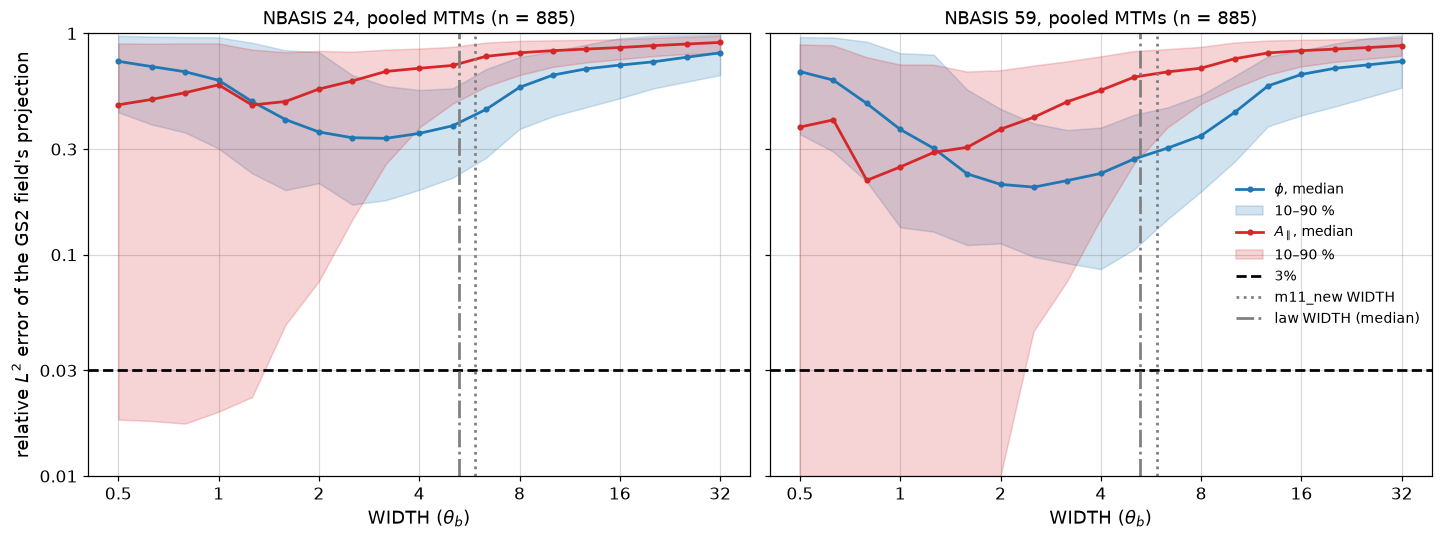

In [11]:
grid = range(len(projection_widths))
# check of the projection code on GS2's own grid: a Gaussian of width s*WIDTH needs the model's count
gs2_theta = gs2_scans["n1000"].gk_output.data.theta.values
for s, width in ((0.5, 4.0), (2.0, 1.0)):
    values, step = np.exp(-gs2_theta ** 2 / (2 * (s * width) ** 2)), np.gradient(gs2_theta)
    coefficients = (hermite_functions(gs2_theta / width) / np.sqrt(width)) @ (values * step)
    error = np.sqrt(np.maximum(1 - np.cumsum(coefficients ** 2) / (values ** 2 * step).sum(), 0))
    assert abs((int(np.argmax(error <= target_error)) + 1) - model_nbasis(s, "even")) <= 1, (s, width)
print("projection reproduces the Gaussian model's count on the GS2 grid")

needed = {field: mtm[[f"{field}_projected_needed_{j}" for j in grid]].to_numpy(float) for field in fields}
error = {(field, nbasis): mtm[[f"{field}_projected_error_{nbasis}_{j}" for j in grid]].to_numpy(float) for field in fields for nbasis in (24, nbasis_cap)}
worst = {nbasis: np.maximum(error[("phi", nbasis)], error[("apar", nbasis)]) for nbasis in (24, nbasis_cap)}   # the worse of the two fields


def at_width(table, width):
    j = np.abs(np.log(projection_widths)[None, :] - np.log(np.broadcast_to(width, len(table)))[:, None]).argmin(1)
    return table[np.arange(len(table)), j]


best_fixed_width = float(projection_widths[np.median(worst[nbasis_cap], 0).argmin()])
projection = pd.DataFrame(dict(draw=mtm.draw.values,
                               phi_needed_law=at_width(needed["phi"], settings.width.values), apar_needed_law=at_width(needed["apar"], settings.width.values),
                               phi_error_law_59=at_width(error[("phi", nbasis_cap)], settings.width.values),
                               apar_error_law_59=at_width(error[("apar", nbasis_cap)], settings.width.values),
                               worst_error_law_59=at_width(worst[nbasis_cap], settings.width.values),
                               worst_error_best_fixed_59=at_width(worst[nbasis_cap], best_fixed_width),
                               worst_error_m11_24=at_width(worst[24], m11_width), worst_error_m11_59=at_width(worst[nbasis_cap], m11_width),
                               worst_error_oracle_59=worst[nbasis_cap].min(1), oracle_width=projection_widths[worst[nbasis_cap].argmin(1)]), index=mtm.index)
error_columns = [column for column in projection if "error" in column]
projection_summary = projection.groupby("draw").agg(
    n=("oracle_width", "size"), phi_needed_law_within_160=("phi_needed_law", lambda n: np.isfinite(n).mean()),
    apar_needed_law_within_160=("apar_needed_law", lambda n: np.isfinite(n).mean()),
    **{f"{column}_median": (column, "median") for column in error_columns},
    **{f"{column}_q90": (column, lambda e: e.quantile(0.9)) for column in error_columns},
    **{f"{column}_within_10pct": (column, lambda e: (e <= 0.1).mean()) for column in error_columns},
    oracle_width_median=("oracle_width", "median"))
projection_summary["best_fixed_width"] = best_fixed_width
projection_summary.to_csv(plots_dir / "projected_error_summary.csv")
print(projection_summary.round(3).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, constrained_layout=True)
for ax, nbasis in zip(axes, (24, nbasis_cap)):
    for field, colour in zip(fields, ("C0", "C3")):
        table = error[(field, nbasis)]
        ax.plot(projection_widths, np.median(table, 0), "-o", ms=3, color=colour, label=f"{field_label[field]}, median")
        ax.fill_between(projection_widths, np.quantile(table, 0.1, 0), np.quantile(table, 0.9, 0), color=colour, alpha=0.2, label="10–90 %")
    ax.axhline(target_error, color="k", ls="--", label=f"{target_error:.0%}")
    ax.axvline(m11_width, color="grey", ls=":", label="m11_new WIDTH")
    ax.axvline(settings.width.median(), color="grey", ls="-.", label="law WIDTH (median)")
    ax.set(xscale="log", yscale="log", ylim=(0.01, 1), xlabel=r"WIDTH ($\theta_b$)", title=f"NBASIS {nbasis}, pooled MTMs (n = {len(mtm)})")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.xaxis.set_minor_locator(NullLocator()); ax.set_xticks([0.5, 1, 2, 4, 8, 16, 32])
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.yaxis.set_minor_locator(NullLocator()); ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1])
axes[0].set_ylabel(r"relative $L^2$ error of the GS2 field's projection")
axes[1].legend(fontsize=9)
fig.savefig(plots_dir / "projected_error_vs_width.png", dpi=150); fig.savefig(plots_dir / "projected_error_vs_width.pdf")
plt.show()

## Retrospective: does the width mismatch predict failure in the existing arms?
No runs. Arms on both draws: `m11_new` (WIDTH 5.893, NBASIS 24), `law2 rule` (`extent_rule_tf035_law2`, per-case WIDTH, NBASIS 8–59),
`law2 maxbasis` (`extent_maxbasis_law2_s100`, WIDTH $=1.6675K$, NBASIS 59), `fw174` (WIDTH 1.74, NBASIS 12). All FIND_WIDTH F.
Per MTM (paired: every arm built the case): GFTM's dominant mode (argmax $\gamma$); **detection** = $\gamma>0$, $\omega<0$, $T>0.15$
($T$ from pyro `FieldLine` on the GFTM $A_\parallel$); $|\log_{10}(\gamma_{\rm GFTM}/\gamma_{\rm GS2})|$ with misses ($\gamma\le0$) $+\infty$;
extent ratio $E_{\rm GFTM}/E_{\rm GS2}$ per field, both in $\theta$ (like-for-like: GFTM's eigenfunction is written on the Miller angle).
Plotted against $s_f=W_f/{\rm WIDTH}_{\rm used}$, in equal-width bins of $\log s_f$ (bins with fewer than 10 cases dropped).

draw                                   n1000                                      n300                                 
arm                                    fw174 law2 maxbasis law2 rule  m11_new    fw174 law2 maxbasis law2 rule  m11_new
n                                    672.000       672.000   672.000  672.000  199.000       199.000   199.000  199.000
detected                               0.499         0.826     0.787    0.726    0.467         0.879     0.759    0.719
medlog                                 0.478         0.341     0.380    0.272    0.410         0.374     0.385    0.259
s_phi_median                           4.485         5.815     2.908    1.324    4.616         5.610     2.919    1.363
s_apar_median                          3.202         3.585     1.874    0.945    3.232         3.783     1.924    0.954
phi_extent_ratio_median                0.370         0.671     0.613    0.878    0.337         0.681     0.640    0.881
apar_extent_ratio_median               0

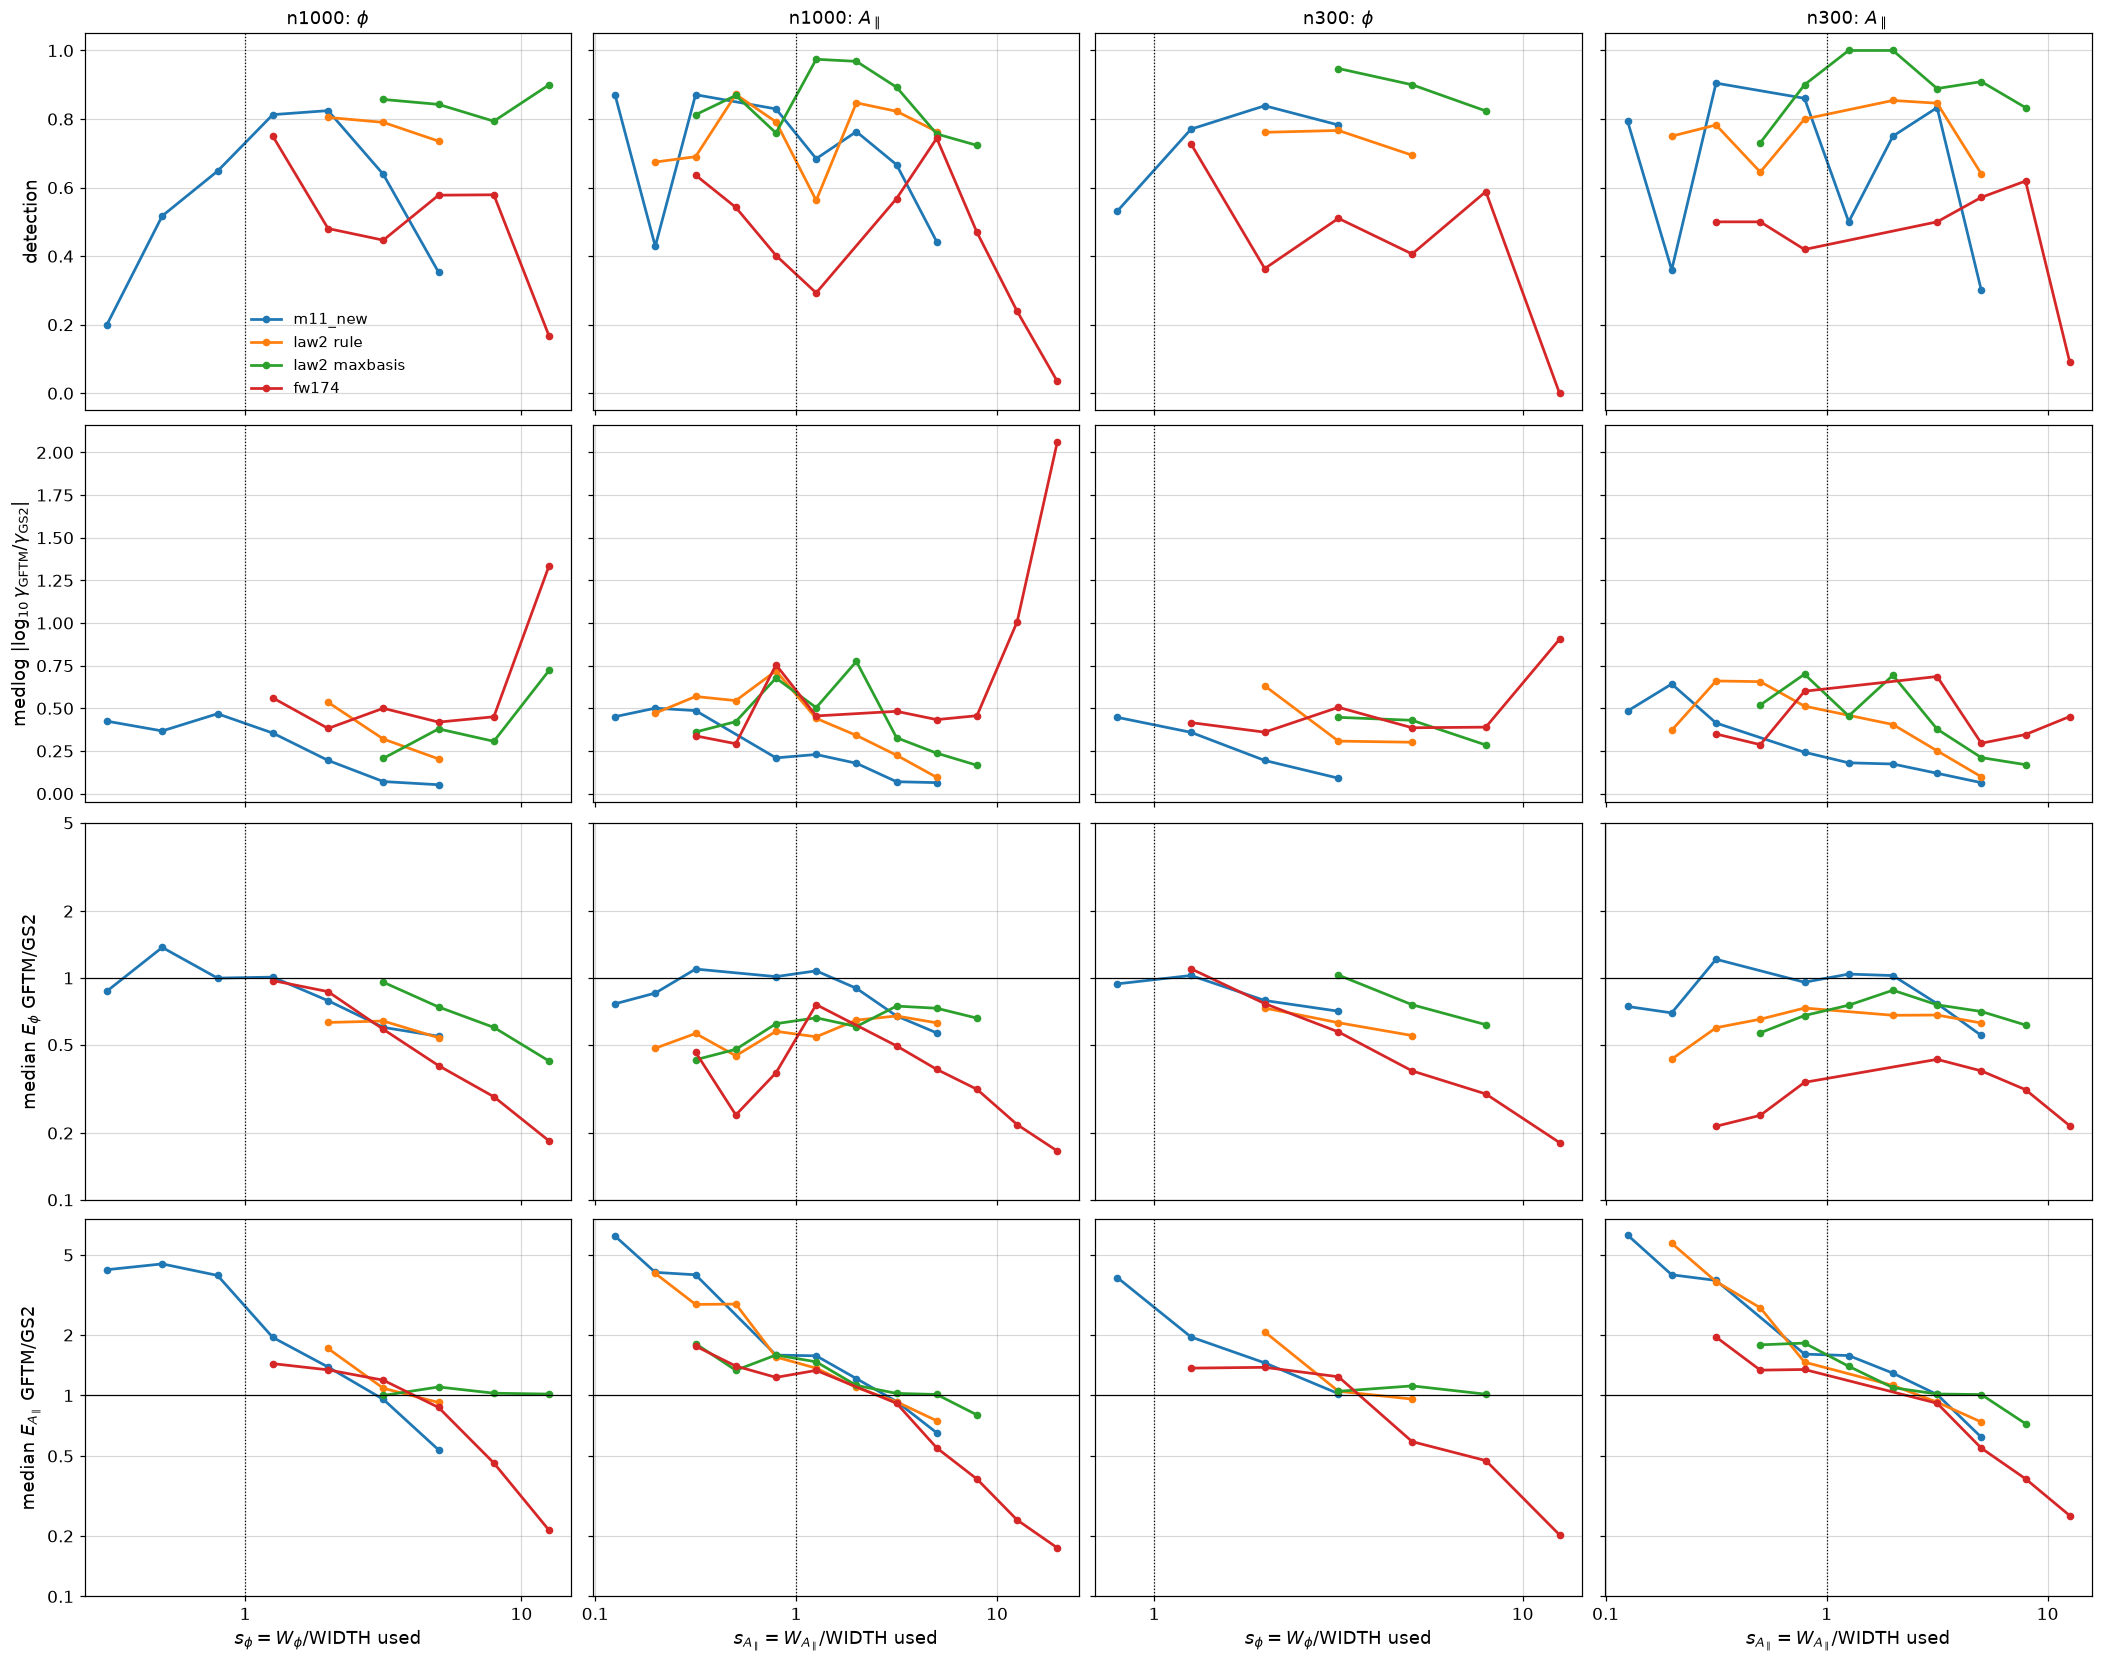

In [12]:
def load_arm(args):
    draw, arm = args
    leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE/NSTX_MTM" / draws[draw] / arms[arm]
    cube_dir = leaf / "pyro_cube" if (leaf / "pyro_cube").is_dir() else leaf
    scan = PyroHypercube(pyro=Pyro(gk_file=cube_dir / "pyroscan_base.input", gk_code="GFTM"), pyroscan_json=cube_dir / "pyroscan.json",
                         base_directory=leaf, file_name="input.gftm")
    scan.load_gk_output(netcdf_file=cube_dir / ("cube.nc" if (cube_dir / "cube.nc").exists() else "pyroscan.nc"))
    output = scan.gk_output.data
    wanted = set(mtm[mtm.draw == draw]["sample"])
    width_used = (output.WIDTH.values if "WIDTH" in output.coords else output.width_used.values if "width_used" in output.coords
                  else np.full(output.sizes["sample"], m11_width))
    gs2_extent = mtm[mtm.draw == draw].set_index("sample")
    rows = []
    for i, name in enumerate(output.sample_name.values):
        if str(name) not in wanted:
            continue
        sample_output = output.isel(sample=i)
        gamma = sample_output.growth_rate.pint.dequantify().values
        dominant = int(np.where(np.isfinite(gamma), gamma, -np.inf).argmax())
        eigenfunctions = sample_output.eigenfunctions.isel(mode=dominant).pint.dequantify().squeeze()
        apar = eigenfunctions.sel(field="apar").dropna("theta").sortby("theta")
        tearing = (FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset({"apar": apar}))).compute_linear_tearing_parameter()
                   if apar.size and np.abs(apar).max() > 0 else np.nan)
        row = dict(draw=draw, arm=arm, sample=str(name), width_used=float(width_used[i]), gamma=float(gamma[dominant]),
                   omega=mc.ION_DIRECTION * float(sample_output.mode_frequency.pint.dequantify().values[dominant]), T=float(np.squeeze(tearing)))
        for field in fields:
            values = eigenfunctions.sel(field=field).dropna("theta").sortby("theta")
            row[f"{field}_extent_ratio"] = (extent_95(np.abs(values.values) ** 2, values.theta.values) / gs2_extent.loc[str(name), f"{field}_extent_theta"]
                                            if np.isfinite(row["gamma"]) and values.size and np.abs(values.values).max() > 0 else np.nan)
        rows.append(row)
    return pd.DataFrame(rows)


with get_context("fork").Pool(n_cpu) as pool:
    retro = pd.concat(pool.map(load_arm, [(draw, arm) for draw in draws for arm in arms]), ignore_index=True)
retro = retro.merge(mtm[["draw", "sample", "gamma", "phi_width", "apar_width", "phi_censored", "apar_censored"]].rename(columns=dict(gamma="gamma_gs2")),
                    on=["draw", "sample"], validate="many_to_one")
built = retro.groupby(["draw", "sample"]).arm.nunique() == len(arms)
retro = retro.join(built.rename("paired"), on=["draw", "sample"])
retro = retro[retro.paired].copy()
retro["detected"] = (retro.gamma > 0) & (retro.omega < 0) & (retro["T"] > mc.T_TEAR)
retro["log_error"] = np.where(retro.gamma > 0, np.abs(np.log10(retro.gamma.clip(lower=1e-300) / retro.gamma_gs2)), np.inf)
for field in fields:
    retro[f"s_{field}"] = retro[f"{field}_width"] / retro.width_used
retro_summary = retro.groupby(["draw", "arm"]).agg(n=("sample", "size"), detected=("detected", "mean"), medlog=("log_error", "median"),
                                                   s_phi_median=("s_phi", "median"), s_apar_median=("s_apar", "median"),
                                                   phi_extent_ratio_median=("phi_extent_ratio", "median"), apar_extent_ratio_median=("apar_extent_ratio", "median"))
s_bins = np.geomspace(0.01, 100, 21)
for field in fields:
    retro[f"s_{field}_bin"] = pd.cut(retro[f"s_{field}"], s_bins)
    for (draw, arm), rows in retro.groupby(["draw", "arm"]):
        within = rows[(rows[f"s_{field}"] >= 1 / 2) & (rows[f"s_{field}"] <= 2)]
        retro_summary.loc[(draw, arm), f"detected_s_{field}_within_2"] = within.detected.mean()
        retro_summary.loc[(draw, arm), f"detected_s_{field}_outside_2"] = rows.drop(within.index).detected.mean()
        retro_summary.loc[(draw, arm), f"spearman_detected_vs_abs_log_s_{field}"] = stats.spearmanr(abs(np.log(rows[f"s_{field}"])), rows.detected)[0]
retro_summary.to_csv(plots_dir / "retrospective_summary.csv")
print(retro_summary.round(3).T.to_string())

metrics = {"detected": ("detection", lambda values: values.mean()), "log_error": (r"medlog $|\log_{10}\gamma_{\rm GFTM}/\gamma_{\rm GS2}|$", lambda values: values.median()),
           "phi_extent_ratio": (r"median $E_\phi$ GFTM/GS2", lambda values: values.median()),
           "apar_extent_ratio": (r"median $E_{A_\parallel}$ GFTM/GS2", lambda values: values.median())}
fig, axes = plt.subplots(len(metrics), 4, figsize=(19, 15), sharex="col", sharey="row", constrained_layout=True)
for column, (draw, field) in enumerate([(draw, field) for draw in draws for field in fields]):
    for arm_index, arm in enumerate(arms):
        rows = retro[(retro.draw == draw) & (retro.arm == arm)]
        grouped = rows.groupby(f"s_{field}_bin", observed=True)
        enough = grouped.size() >= 10
        centres = np.array([np.sqrt(interval.left * interval.right) for interval in grouped.size().index])[enough.values]
        for row, (metric, (label, reduce)) in enumerate(metrics.items()):
            values = grouped[metric].apply(reduce)[enough.values]
            axes[row, column].plot(centres, values, "-o", ms=4, color=f"C{arm_index}", label=arm)
            axes[row, 0].set_ylabel(label)
    axes[0, column].set_title(f"{draw}: {field_label[field]}")
    axes[-1, column].set_xlabel({"phi": r"$s_\phi=W_\phi/$WIDTH used", "apar": r"$s_{A_\parallel}=W_{A_\parallel}/$WIDTH used"}[field])
    for row in range(len(metrics)):
        ax = axes[row, column]
        ax.axvline(1, color="k", lw=0.8, ls=":")
        ax.set_xscale("log"); ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.xaxis.set_minor_locator(NullLocator())
for row in (2, 3):
    axes[row, 0].set_yscale("log"); axes[row, 0].yaxis.set_major_formatter(StrMethodFormatter("{x:g}")); axes[row, 0].yaxis.set_minor_locator(NullLocator()); axes[row, 0].set_yticks([0.1, 0.2, 0.5, 1, 2, 5])
    for column in range(4):
        axes[row, column].axhline(1, color="k", lw=0.8)
axes[0, 0].legend(fontsize=10)
fig.savefig(plots_dir / "retrospective_vs_width_ratio.png", dpi=150); fig.savefig(plots_dir / "retrospective_vs_width_ratio.pdf")
plt.show()

Low-level view behind it: every paired MTM per arm, $s_{A_\parallel}$ against $s_\phi$, detected (filled) and not detected (open red).

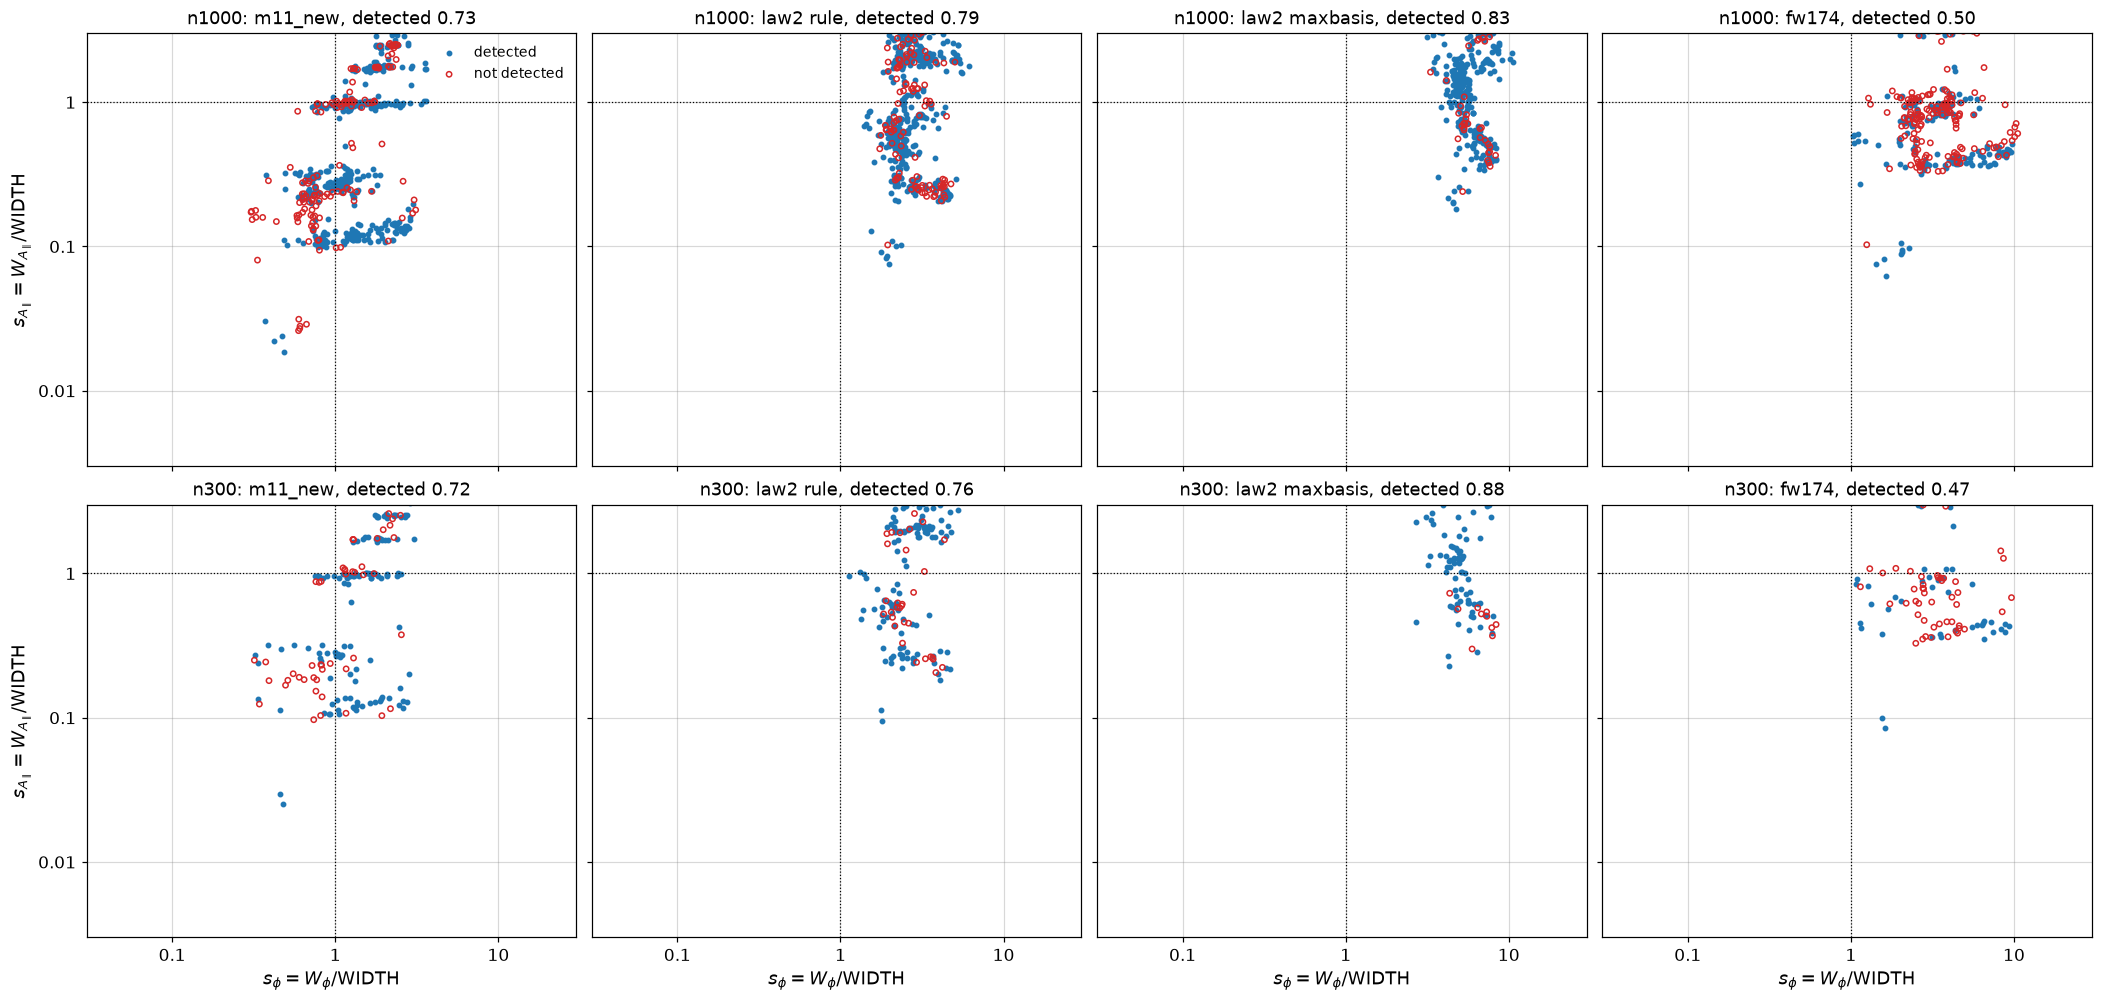

In [13]:
fig, axes = plt.subplots(2, len(arms), figsize=(19, 9), sharex=True, sharey=True, constrained_layout=True)
for row, draw in enumerate(draws):
    for column, arm in enumerate(arms):
        ax = axes[row, column]
        rows = retro[(retro.draw == draw) & (retro.arm == arm)]
        ax.scatter(rows.s_phi[rows.detected], rows.s_apar[rows.detected], s=8, c="C0", label="detected")
        ax.scatter(rows.s_phi[~rows.detected], rows.s_apar[~rows.detected], s=12, facecolors="none", edgecolors="C3", label="not detected")
        ax.axvline(1, color="k", lw=0.8, ls=":"); ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.set(xscale="log", yscale="log", xlim=(0.03, 30), ylim=(0.003, 3), title=f"{draw}: {arm}, detected {rows.detected.mean():.2f}")
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(StrMethodFormatter("{x:g}")); axis.set_minor_locator(NullLocator())
    axes[row, 0].set_ylabel(r"$s_{A_\parallel}=W_{A_\parallel}/$WIDTH")
for ax in axes[-1]:
    ax.set_xlabel(r"$s_\phi=W_\phi/$WIDTH")
axes[0, 0].legend(fontsize=9)
fig.savefig(plots_dir / "retrospective_width_ratio_scatter.png", dpi=150); fig.savefig(plots_dir / "retrospective_width_ratio_scatter.pdf")
plt.show()

## Check figures: the map against GFTM, and the KBM cross-check
Left: median $E/W$ of the NBASIS-2 GFTM fields against WIDTH, in $\theta$ (what qp5.49 calibrated) and in $\theta_b$ (pyro map), with
the analytic factors. Right: per KBM, the analytic $\theta_b$ width against qp5.49's run-calibrated width.

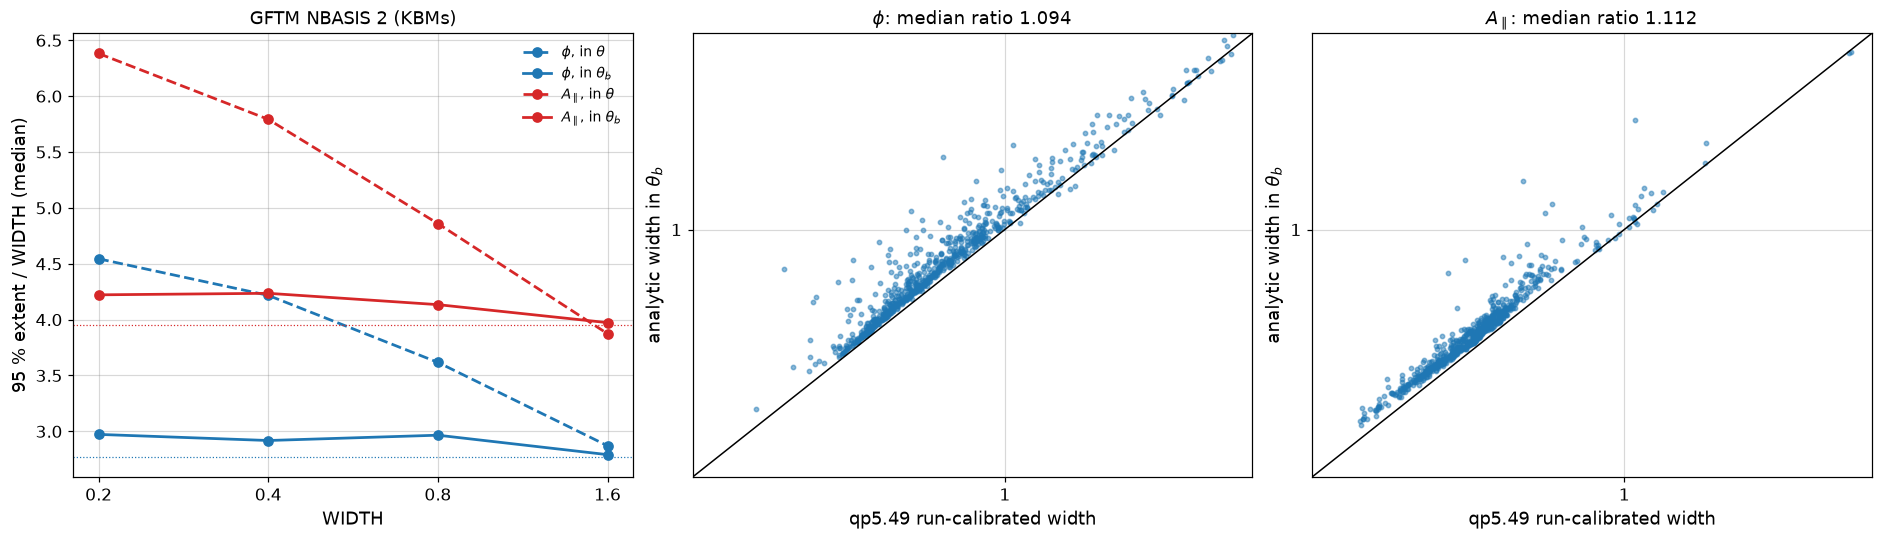

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
for field, colour in zip(fields, ("C0", "C3")):
    grouped = code_check[code_check.field == field].groupby("width")
    axes[0].plot(grouped.extent_theta_over_width.median().index, grouped.extent_theta_over_width.median(), "--o", color=colour, label=rf"{field_label[field]}, in $\theta$")
    axes[0].plot(grouped.extent_over_width.median().index, grouped.extent_over_width.median(), "-o", color=colour, label=rf"{field_label[field]}, in $\theta_b$")
    axes[0].axhline(analytic_factor[kbm_parity[field]], color=colour, lw=0.8, ls=":")
axes[0].set(xscale="log", xlabel="WIDTH", ylabel="95 % extent / WIDTH (median)", title="GFTM NBASIS 2 (KBMs)")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); axes[0].xaxis.set_minor_locator(NullLocator()); axes[0].set_xticks(check_widths)
axes[0].legend(fontsize=9)
for ax, field in zip(axes[1:], fields):
    rows = kbm[finite[field]]
    ax.scatter(rows[f"{field}_width_calibrated"], rows[f"{field}_width_analytic"], s=8, alpha=0.5)
    limits = [0.15, 4.5]
    ax.plot(limits, limits, "k", lw=1, marker="")
    ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits, xlabel="qp5.49 run-calibrated width",
           ylabel=r"analytic width in $\theta_b$", title=f"{field_label[field]}: median ratio {kbm_summary.loc[field, 'ratio_median']:.3f}")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(StrMethodFormatter("{x:g}")); axis.set_minor_locator(NullLocator())
fig.savefig(plots_dir / "check_map_and_kbm.png", dpi=150); fig.savefig(plots_dir / "check_map_and_kbm.pdf")
plt.show()